# Mendeley Dengue — Manuscript-Aligned Reproducibility Pipeline

This notebook is arranged to match the final manuscript workflow:

**Original Mendeley dataset (1,003 records) → exclude 14 missing outcome labels → final labelled cohort (989) → stratified development/test split (791/198) → leakage-safe preprocessing → repeated 5×5 baseline comparison → paired statistical testing → utility-weight sensitivity → Random Forest selection → budget-matched Canonical RPO vs Random Search (274 unique evaluations each) → five-seed RPO stability → sigmoid calibration → development-only calibrated OOF threshold selection (0.52) → locked independent-test evaluation → calibration diagnostics → prevalence-sensitive PPV/NPV analysis → 2,000-resample conditional bootstrap uncertainty → imputation sensitivity → global SHAP analysis → manuscript result export.**

## Important methodological rules
- The independent test set is isolated before preprocessing, model selection, optimization, calibration, and threshold selection.
- The test set is used only for the final locked evaluation.
- The manuscript does **not** claim that RPO is intrinsically superior to conventional tuning.
- RPO–TPE and optional repeated nested whole-pipeline experiments are excluded from this manuscript-aligned notebook because they are not part of the final reported workflow.
- SHAP explanations describe the fitted Random Forest model and are not interpreted as clinical causation.

## Runtime note
Canonical RPO, budget-matched Random Search, and five-seed RPO stability are computationally expensive. Their executed outputs from the completed revision run are retained where available. Downstream figure/diagnostic cells use the canonical RPO configuration reported in the manuscript.


## A. Environment and data preparation


In [ ]:
# ================================================================
# 1. Imports and dependency check
# ================================================================
import os
import sys
import time
import json
import math
import random
import zipfile
import warnings
import subprocess
from pathlib import Path
from typing import Any, Dict, List, Tuple, Optional

warnings.filterwarnings("ignore")

required_packages = {
    "xgboost": "xgboost",
    "shap": "shap",
    "statsmodels": "statsmodels",
}

for import_name, pip_name in required_packages.items():
    try:
        __import__(import_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, norm
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

from xgboost import XGBClassifier

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    cross_validate,
    cross_val_predict,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss,
    log_loss,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
)

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [ ]:
# ================================================================
# 2. Global configuration
# ================================================================
RANDOM_STATE = 42
TEST_SIZE = 0.20

# Baseline evaluation
BASELINE_CV_SPLITS = 5
BASELINE_CV_REPEATS = 5

# Prespecified model-selection utility
UTILITY_WEIGHTS = {
    "Recall": 0.35,
    "F1": 0.25,
    "ROC_AUC": 0.20,
    "Balanced_Accuracy": 0.20,
}

# Random Forest / RPO search space
LOWER_BOUNDS = np.array([100, 3, 2, 1, 0.30, 0], dtype=float)
UPPER_BOUNDS = np.array([800, 30, 20, 10, 1.00, 1], dtype=float)

RPO_POPULATION_SIZE = 10
RPO_ITERATIONS = 15
OPTIMIZATION_CV_SPLITS = 5

# Canonical configuration reported in the manuscript.
# This fixed copy allows downstream figures/diagnostics to be reproduced
# without repeating the expensive optimizer search.
CANONICAL_RF_PARAMS = {
    "n_estimators": 209,
    "max_depth": 3,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": 0.30,
    "class_weight": None,
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

# Calibration and thresholding
CALIBRATION_INNER_CV = 3
FINAL_CALIBRATION_CV = 5
MINIMUM_SENSITIVITY = 0.90
THRESHOLD_GRID = np.arange(0.05, 0.951, 0.01)

# Bootstrap
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 4242  # deterministic for future reruns

# Reviewer sensitivity analyses
RUN_RPO_MULTI_SEED = True
RPO_STABILITY_SEEDS = [11, 22, 33, 44, 55]
RUN_UTILITY_SENSITIVITY = True
UTILITY_RANDOM_DRAWS = 5000
RUN_IMPUTATION_SENSITIVITY = True
RUN_SHAP = True

# Output folder
OUTPUT_DIR = Path("Mendeley_Dengue_Reviewer_Outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

print("Configuration ready.")
print("Output directory:", OUTPUT_DIR.resolve())


Configuration ready.
Output directory: /content/Mendeley_Dengue_Reviewer_Outputs


In [ ]:
# ================================================================
# 3. Load the original Mendeley data (CSV or ZIP)
# Reviewer revision: supports the supplied standalone CSV.
# ================================================================
from pathlib import Path
import zipfile
import pandas as pd

CSV_FILENAME = "/content/Dengue diseases dataset.csv"
ZIP_FILENAME = "Predictive Clinical Dataset for Dengue Fever Using Vital Signs and Blood Parameters.zip"
SEARCH_DIRS = [Path('/content'), Path('/mnt/data'), Path.cwd()]

def locate_input_file():
    # Prefer the original CSV supplied for this revision.
    for folder in SEARCH_DIRS:
        candidate = folder / CSV_FILENAME
        if candidate.is_file():
            return candidate
    for folder in SEARCH_DIRS:
        candidate = folder / ZIP_FILENAME
        if candidate.is_file():
            return candidate
    # Colab browser upload fallback.
    try:
        from google.colab import files
        print('Upload the original Dengue diseases dataset.csv (or source ZIP).')
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError('No dataset was uploaded.')
        return Path(next(iter(uploaded)))
    except ImportError:
        raise FileNotFoundError(
            f"Could not find {CSV_FILENAME!r}. Place it in the notebook folder "
            "or upload it to the Colab runtime."
        )

INPUT_PATH = locate_input_file()
if INPUT_PATH.suffix.lower() == '.csv':
    raw_df = pd.read_csv(INPUT_PATH)
elif INPUT_PATH.suffix.lower() == '.zip':
    with zipfile.ZipFile(INPUT_PATH, 'r') as archive:
        csv_files = [n for n in archive.namelist() if n.lower().endswith('.csv')]
        if len(csv_files) != 1:
            raise ValueError(f'Expected exactly one CSV file in ZIP; found: {csv_files}')
        with archive.open(csv_files[0]) as stream:
            raw_df = pd.read_csv(stream)
else:
    raise ValueError('Please upload a CSV or ZIP file, not another file type.')

print('Dataset source file:', INPUT_PATH.name)
print('Original data shape:', raw_df.shape)
print('Columns:', raw_df.columns.tolist())
display(raw_df.head())


Dataset source file: Dengue diseases dataset.csv
Original data shape: (1003, 9)
Columns: ['Age', 'Sex', 'Haemoglobin', 'WBC Count', 'Differential Count', 'RBC PANEL', 'Platelet Count', 'PDW', 'Final Output']


,Age,Sex,Haemoglobin,WBC Count,Differential Count,RBC PANEL,Platelet Count,PDW,Final Output
0,43,Male,12.6,2200.0,1,1,62000.0,11.0,1.0
1,45,Male,13.2,3000.0,0,1,17000.0,17.0,1.0
2,50,Female,11.0,3300.0,1,1,19000.0,16.3,1.0
3,57,Female,11.9,3500.0,1,0,29000.0,14.0,1.0
4,51,Female,13.0,3100.0,0,1,30000.0,14.5,1.0


In [ ]:
# ================================================================
# 4. Dataset audit and labelled cohort construction
# ================================================================
EXPECTED_COLUMNS = [
    "Age",
    "Sex",
    "Haemoglobin",
    "WBC Count",
    "Differential Count",
    "RBC PANEL",
    "Platelet Count",
    "PDW",
    "Final Output",
]

missing_expected = [c for c in EXPECTED_COLUMNS if c not in raw_df.columns]
if missing_expected:
    raise ValueError(f"Missing expected Mendeley columns: {missing_expected}")

audit_before = pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "missing_n": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(3),
    "unique_n": raw_df.nunique(dropna=True),
})
display(audit_before)

print("\nTarget distribution including missing:")
print(raw_df["Final Output"].value_counts(dropna=False).sort_index())

print("\nExact duplicate rows:", int(raw_df.duplicated().sum()))

# Supervised modelling requires known outcome labels.
df = raw_df.loc[raw_df["Final Output"].notna(), EXPECTED_COLUMNS].copy()
df["Final Output"] = df["Final Output"].astype(int)

print("\nLabelled modelling cohort:", df.shape)
print(df["Final Output"].value_counts().sort_index())
print((df["Final Output"].value_counts(normalize=True).sort_index() * 100).round(2))

audit_labelled = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(3),
    "unique_n": df.nunique(dropna=True),
})
audit_labelled.to_csv(OUTPUT_DIR / "dataset_audit_labelled.csv")
display(audit_labelled)

# Preserve unusual/extreme source values; do not silently cap/delete.
numeric_summary = df.select_dtypes(include=np.number).describe().T
numeric_summary.to_csv(OUTPUT_DIR / "numeric_summary.csv")
display(numeric_summary)

,dtype,missing_n,missing_pct,unique_n
Age,int64,0,0.000,99
Sex,object,0,0.000,3
Haemoglobin,float64,0,0.000,53
WBC Count,float64,24,2.393,74
Differential Count,int64,0,0.000,2
RBC PANEL,int64,0,0.000,2
Platelet Count,float64,17,1.695,355
PDW,float64,19,1.894,242
Final Output,float64,14,1.396,2



Target distribution including missing:
Final Output
0.0    320
1.0    669
NaN     14
Name: count, dtype: int64

Exact duplicate rows: 0

Labelled modelling cohort: (989, 9)
Final Output
0    320
1    669
Name: count, dtype: int64
Final Output
0    32.36
1    67.64
Name: proportion, dtype: float64


,dtype,missing_n,missing_pct,unique_n
Age,int64,0,0.000,99
Sex,object,0,0.000,3
Haemoglobin,float64,0,0.000,53
WBC Count,float64,24,2.427,74
Differential Count,int64,0,0.000,2
RBC PANEL,int64,0,0.000,2
Platelet Count,float64,16,1.618,354
PDW,float64,19,1.921,242
Final Output,int64,0,0.000,2


,count,mean,std,min,25%,50%,75%,max
Age,989.0,42.199191,20.941111,3.0,27.0,40.0,55.0,120.0
Haemoglobin,989.0,13.712942,1.484111,11.0,12.6,13.7,15.0,25.0
WBC Count,965.0,4338.031088,2344.529755,2000.0,2600.0,3200.0,6200.0,10900.0
Differential Count,989.0,0.939333,0.238840,0.0,1.0,1.0,1.0,1.0
RBC PANEL,989.0,0.938322,0.240692,0.0,1.0,1.0,1.0,1.0
Platelet Count,973.0,114702.241521,89421.766107,10000.0,46000.0,93000.0,162500.0,500000.0
PDW,970.0,22.848866,14.692872,1.0,14.0,17.8,28.2,215.0
Final Output,989.0,0.676441,0.468071,0.0,0.0,1.0,1.0,1.0


In [ ]:
# ================================================================
# 5. Define predictors and create the locked development/test split
# ================================================================
TARGET = "Final Output"

CONTINUOUS_FEATURES = [
    "Age",
    "Haemoglobin",
    "WBC Count",
    "Platelet Count",
    "PDW",
]

BINARY_FEATURES = [
    "Differential Count",
    "RBC PANEL",
]

CATEGORICAL_FEATURES = ["Sex"]

FEATURES = CONTINUOUS_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("Development shape:", X_train.shape)
print("Independent test shape:", X_test.shape)
print("\nDevelopment classes:")
print(y_train.value_counts().sort_index())
print("\nTest classes:")
print(y_test.value_counts().sort_index())

split_summary = {
    "Total_labelled": int(len(df)),
    "Development_n": int(len(X_train)),
    "Test_n": int(len(X_test)),
    "Development_class_0": int((y_train == 0).sum()),
    "Development_class_1": int((y_train == 1).sum()),
    "Test_class_0": int((y_test == 0).sum()),
    "Test_class_1": int((y_test == 1).sum()),
}
with open(OUTPUT_DIR / "split_summary.json", "w") as f:
    json.dump(split_summary, f, indent=2)

print("\nTEST SET LOCKED. Do not use it for tuning/calibration/threshold selection.")

Development shape: (791, 8)
Independent test shape: (198, 8)

Development classes:
Final Output
0    256
1    535
Name: count, dtype: int64

Test classes:
Final Output
0     64
1    134
Name: count, dtype: int64

TEST SET LOCKED. Do not use it for tuning/calibration/threshold selection.


## Reviewer revision — Step 1: Data validity and outcome-label audit

Run this section **immediately after** the original **"Define predictors and create the locked development/test split"** cell. Run the existing import, configuration, data-loading, and cohort-construction cells first. You do **not** need to run RPO or any later time-consuming training cells for this step.

This is a **record-level audit**, not proof of unique patients or diagnostic validity:

- Record/predictor duplicates and identical predictor profiles across development and test partitions can be checked from the CSV.
- The CSV does **not** include patient IDs, visit IDs, or dates. Accordingly, separate rows **cannot** be established as separate patients from this file.
- The names and coding of `Final Output`, `Differential Count`, `RBC PANEL`, and `Sex = Child` need clarification from the dataset publication/authors. A statistical association with a label does **not** establish the clinical reference standard.
- The class-conditional predictor tables below use **development data only**. Keep the original test set locked for final assessment, rather than using it to choose features.

**Send the outputs of the next cell for interpretation before moving to Step 2.**

In [ ]:
# ================================================================
# Reviewer Step 1: source-record audit and ambiguous predictor coding
# DOES NOT use test outcomes to select features or train models.
# ================================================================
import pandas as pd

print('== Dataset and class-label audit ==')
print('Original records:', len(raw_df))
print('Unlabeled records:', raw_df['Final Output'].isna().sum())
print('Labeled records:', len(df))
print('Observed labels (meanings require source confirmation):')
print(df['Final Output'].value_counts(dropna=False).sort_index())

print('\n== Exact record and predictor duplicates ==')
print('Exact duplicate rows, original source:', int(raw_df.duplicated().sum()))
print('Exact duplicate rows, labeled cohort:', int(df.duplicated().sum()))
print('Repeated predictor vectors, labeled cohort:', int(df[FEATURES].duplicated().sum()))

# Identical predictor vectors assigned different outcomes are especially noteworthy.
label_conflicts = df.groupby(FEATURES, dropna=False)['Final Output'].nunique()
print('Identical predictor profiles with conflicting outcome labels:',
      int((label_conflicts > 1).sum()))

# This checks exact predictor-value overlap only. It does not establish
# that two different-looking rows cannot belong to the same person.
train_profiles = X_train.drop_duplicates()
test_profiles = X_test.drop_duplicates()
common_profiles = train_profiles.merge(test_profiles, on=FEATURES, how='inner')
print('Exact shared predictor profiles in development and test:', len(common_profiles))

print('\n== Patient and visit identity fields ==')
identity_columns = [c for c in raw_df.columns if any(token in c.lower()
                    for token in ('patient', 'subject', 'participant', 'encounter', 'visit', 'record id', 'date'))]
print('Available patient/visit-identifying columns:', identity_columns if identity_columns else 'None')
print('Caution: no patient/visit identifier means patient uniqueness remains unverified.')

print('\n== Ambiguous variables by outcome on DEVELOPMENT DATA ONLY ==')
for col in ['Sex', 'Differential Count', 'RBC PANEL']:
    print(f'\n{col}:')
    counts = pd.crosstab(X_train[col].fillna('<Missing>'),
                         y_train.rename('Final Output'), dropna=False)
    display(counts)
    counts.to_csv(OUTPUT_DIR / ('reviewer1_' + col.lower().replace(' ', '_') + '_development_table.csv'))

summary = pd.DataFrame([{
    'source_n': len(raw_df),
    'labeled_n': len(df),
    'development_n': len(X_train),
    'test_n': len(X_test),
    'source_exact_duplicates_n': int(raw_df.duplicated().sum()),
    'labeled_exact_duplicates_n': int(df.duplicated().sum()),
    'repeated_predictor_vectors_n': int(df[FEATURES].duplicated().sum()),
    'conflicting_label_profiles_n': int((label_conflicts > 1).sum()),
    'shared_predictor_profiles_across_split_n': len(common_profiles),
    'patient_uniqueness_verified': False,
    'clinical_reference_standard_verified': False,
}])
summary.to_csv(OUTPUT_DIR / 'reviewer1_step1_dataset_audit.csv', index=False)
print('\nReviewer audit saved to:', OUTPUT_DIR / 'reviewer1_step1_dataset_audit.csv')


== Dataset and class-label audit ==
Original records: 1003
Unlabeled records: 14
Labeled records: 989
Observed labels (meanings require source confirmation):
Final Output
0    320
1    669
Name: count, dtype: int64

== Exact record and predictor duplicates ==
Exact duplicate rows, original source: 0
Exact duplicate rows, labeled cohort: 0
Repeated predictor vectors, labeled cohort: 0
Identical predictor profiles with conflicting outcome labels: 0
Exact shared predictor profiles in development and test: 0

== Patient and visit identity fields ==
Available patient/visit-identifying columns: None
Caution: no patient/visit identifier means patient uniqueness remains unverified.

== Ambiguous variables by outcome on DEVELOPMENT DATA ONLY ==

Sex:


Final Output,0,1
Sex,,
Child,8,22
Female,117,241
Male,131,272



Differential Count:


Final Output,0,1
Differential Count,,
0,0,45
1,256,490



RBC PANEL:


Final Output,0,1
RBC PANEL,,
0,0,51
1,256,484



Reviewer audit saved to: Mendeley_Dengue_Reviewer_Outputs/reviewer1_step1_dataset_audit.csv


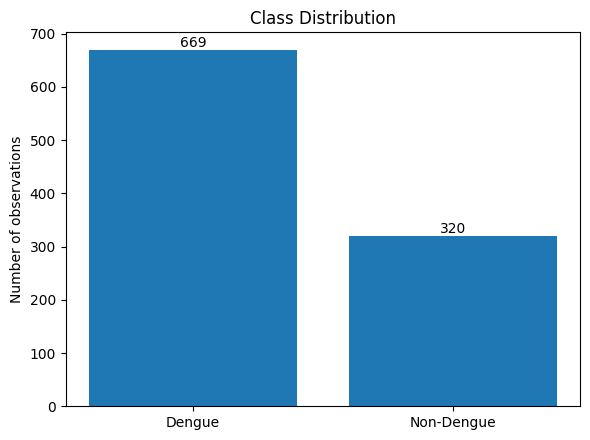

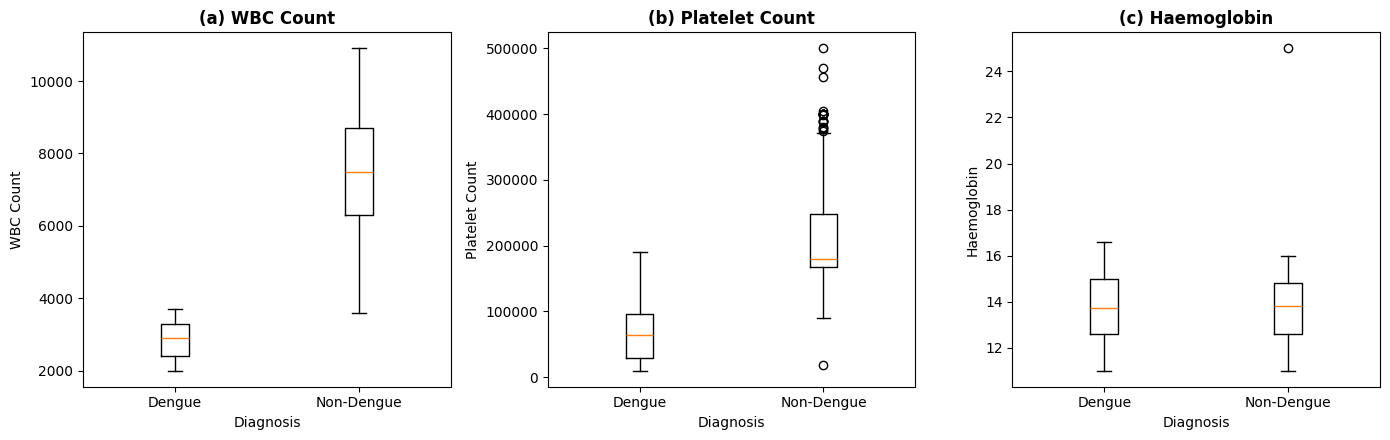

In [ ]:
# ================================================================
# 6. Dataset figures used in the manuscript (Figures 2 and 3)
# ================================================================
# Figure 2: class distribution
class_counts = (
    df["Final Output"]
    .value_counts()
    .reindex([1, 0])
    .rename(index={1: "Dengue", 0: "Non-Dengue"})
)

plt.figure(figsize=(6, 4.5))
bars = plt.bar(class_counts.index, class_counts.values)
plt.ylabel("Number of observations")
plt.title("Class Distribution")
for bar, value in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, value, str(int(value)),
             ha="center", va="bottom")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_2_Class_Distribution.png", dpi=600, bbox_inches="tight")
plt.show()

# Figure 3: selected hematological distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
plot_specs = [
    ("WBC Count", "(a) WBC Count"),
    ("Platelet Count", "(b) Platelet Count"),
    ("Haemoglobin", "(c) Haemoglobin"),
]
groups = [("Dengue", 1), ("Non-Dengue", 0)]

for ax, (feature, title) in zip(axes, plot_specs):
    data = [
        df.loc[df["Final Output"] == label, feature].dropna().to_numpy()
        for _, label in groups
    ]
    ax.boxplot(data, labels=[name for name, _ in groups])
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Diagnosis")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_3_Selected_Hematological_Distributions.png",
            dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
# ================================================================
# 6. Leakage-safe preprocessing
# ================================================================
def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

def build_preprocessor(imputation: str = "median") -> ColumnTransformer:
    if imputation == "median":
        continuous_imputer = SimpleImputer(strategy="median")
    elif imputation == "knn":
        continuous_imputer = KNNImputer(n_neighbors=5, weights="distance")
    else:
        raise ValueError("imputation must be 'median' or 'knn'")

    continuous_pipe = Pipeline([
        ("imputer", continuous_imputer),
        ("scaler", StandardScaler()),
    ])

    binary_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
    ])

    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_ohe()),
    ])

    return ColumnTransformer([
        ("continuous", continuous_pipe, CONTINUOUS_FEATURES),
        ("binary", binary_pipe, BINARY_FEATURES),
        ("categorical", categorical_pipe, CATEGORICAL_FEATURES),
    ], remainder="drop")

preprocessor = build_preprocessor("median")
print(preprocessor)

ColumnTransformer(transformers=[('continuous',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Age', 'Haemoglobin', 'WBC Count',
                                  'Platelet Count', 'PDW']),
                                ('binary',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent'))]),
                                 ['Differential Count', 'RBC PANEL']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(ha

## B. Baseline model selection


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 2
# Feature ablation and shortcut-learning investigation
# DEVELOPMENT DATA ONLY - DO NOT USE THE TEST SET
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
import pandas as pd
import numpy as np

feature_sets = {
    "All 8 predictors": FEATURES,

    "Without binary indicators": [
        f for f in FEATURES
        if f not in ["Differential Count", "RBC PANEL"]
    ],

    "Without ambiguous variables": [
        f for f in FEATURES
        if f not in ["Sex", "Differential Count", "RBC PANEL"]
    ],

    "WBC only": ["WBC Count"],

    "WBC and Platelet": ["WBC Count", "Platelet Count"],

    "Without WBC": [
        f for f in FEATURES if f != "WBC Count"
    ],

    "Without WBC and Platelet": [
        f for f in FEATURES
        if f not in ["WBC Count", "Platelet Count"]
    ]
}

def make_subset_preprocessor(columns):
    transformers = []

    numeric = [f for f in CONTINUOUS_FEATURES if f in columns]
    binary = [f for f in BINARY_FEATURES if f in columns]
    categorical = [f for f in CATEGORICAL_FEATURES if f in columns]

    if numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric
        ))

    if binary:
        transformers.append((
            "binary",
            SimpleImputer(strategy="most_frequent"),
            binary
        ))

    if categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", make_ohe())
            ]),
            categorical
        ))

    return ColumnTransformer(transformers)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

splits = list(cv.split(X_train, y_train))
results = []

for name, cols in feature_sets.items():

    print("Evaluating:", name)

    model = Pipeline([
        ("preprocessor", make_subset_preprocessor(cols)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=splits,
        scoring={
            "Accuracy": "accuracy",
            "Balanced_Accuracy": "balanced_accuracy",
            "Sensitivity": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=1
    )

    result = {"Feature_Set": name, "No_Features": len(cols)}

    for metric in [
        "Accuracy", "Balanced_Accuracy",
        "Sensitivity", "F1", "ROC_AUC"
    ]:
        result[metric] = scores["test_" + metric].mean()
        result[metric + "_SD"] = scores["test_" + metric].std(ddof=1)

    results.append(result)

ablation_results = pd.DataFrame(results)

display(ablation_results.round(5))

ablation_results.to_csv(
    OUTPUT_DIR / "reviewer_step2_feature_ablation.csv",
    index=False
)

print("\nStep 2 completed successfully.")
print("All experiments used development data only.")


Evaluating: All 8 predictors
Evaluating: Without binary indicators
Evaluating: Without ambiguous variables
Evaluating: WBC only
Evaluating: WBC and Platelet
Evaluating: Without WBC
Evaluating: Without WBC and Platelet


,Feature_Set,No_Features,Accuracy,Accuracy_SD,Balanced_Accuracy,Balanced_Accuracy_SD,Sensitivity,Sensitivity_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD
0,All 8 predictors,8,0.99722,0.00369,0.99692,0.00486,0.99776,0.00407,0.99794,0.00272,0.99991,0.00019
1,Without binary indicators,6,0.99772,0.00310,0.99750,0.00375,0.99813,0.00382,0.99832,0.00229,0.99993,0.00018
2,Without ambiguous variables,5,0.99595,0.00544,0.99578,0.00614,0.99626,0.00603,0.99700,0.00403,0.99986,0.00025
3,WBC only,1,0.98988,0.00914,0.98433,0.01416,1.00000,0.00000,0.99262,0.00661,0.99686,0.00491
4,WBC and Platelet,2,0.99519,0.00526,0.99481,0.00574,0.99589,0.00718,0.99644,0.00390,0.99995,0.00011
5,Without WBC,7,0.98559,0.00741,0.98223,0.00855,0.99178,0.00985,0.98936,0.00549,0.99576,0.00523
6,Without WBC and Platelet,6,0.85788,0.01969,0.81300,0.02692,0.94019,0.02225,0.89951,0.01355,0.90552,0.02223



Step 2 completed successfully.
All experiments used development data only.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 3
# Label-permutation sanity test
# Development data only
# ============================================================

from sklearn.model_selection import (
    StratifiedKFold,
    permutation_test_score
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import numpy as np

permutation_model = Pipeline([
    ("preprocessor", make_subset_preprocessor(FEATURES)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

permutation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

observed_score, null_scores, p_value = permutation_test_score(
    permutation_model,
    X_train[FEATURES],
    y_train,
    scoring="balanced_accuracy",
    cv=permutation_cv,
    n_permutations=50,
    n_jobs=1,
    random_state=42
)

print("STEP 3 - PERMUTATION TEST RESULTS")
print("--------------------------------")
print("Observed balanced accuracy:",
      round(observed_score, 5))
print("Mean shuffled-label accuracy:",
      round(np.mean(null_scores), 5))
print("Maximum shuffled-label accuracy:",
      round(np.max(null_scores), 5))
print("Permutation p-value:",
      round(p_value, 5))

permutation_results = pd.DataFrame({
    "Permutation": np.arange(1, len(null_scores) + 1),
    "Balanced_Accuracy": null_scores
})

permutation_results.to_csv(
    OUTPUT_DIR / "reviewer_step3_permutation.csv",
    index=False
)

print("\nStep 3 completed successfully.")
print("Independent test set was not used.")


STEP 3 - PERMUTATION TEST RESULTS
--------------------------------
Observed balanced accuracy: 0.99617
Mean shuffled-label accuracy: 0.49943
Maximum shuffled-label accuracy: 0.52863
Permutation p-value: 0.01961

Step 3 completed successfully.
Independent test set was not used.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 4
# Near-duplicate and target-proxy investigation
# ============================================================

import pandas as pd
import numpy as np

# Exploratory similarity tolerances
# These are screening rules, NOT validated clinical cutoffs.
tolerances = {
    "Age": 2,
    "Haemoglobin": 0.5,
    "WBC Count": 300,
    "Platelet Count": 10000,
    "PDW": 1.0
}

exact_match_columns = [
    "Sex", "Differential Count", "RBC PANEL"
]

def identify_similar_pairs(left, right, same_set=False):

    matches = np.ones(
        (len(left), len(right)), dtype=bool
    )

    for col in exact_match_columns:
        a = left[col].to_numpy()
        b = right[col].to_numpy()
        matches &= (a[:, None] == b[None, :])

    for col, tolerance in tolerances.items():
        a = left[col].to_numpy(dtype=float)
        b = right[col].to_numpy(dtype=float)

        matches &= (
            np.isfinite(a[:, None])
            & np.isfinite(b[None, :])
            & (np.abs(a[:, None] - b[None, :])
               <= tolerance)
        )

    if same_set:
        matches = np.triu(matches, k=1)

    i, j = np.where(matches)

    return pd.DataFrame({
        "Left_Source_Index": left.index.to_numpy()[i],
        "Right_Source_Index": right.index.to_numpy()[j]
    })


# 1. Near-duplicates within development data
development_pairs = identify_similar_pairs(
    X_train, X_train, same_set=True
)

print("STEP 4 - NEAR-DUPLICATE AUDIT")
print("-----------------------------")
print("Near-similar pairs within development:",
      len(development_pairs))

if not development_pairs.empty:
    a = y_train.loc[
        development_pairs["Left_Source_Index"]
    ].to_numpy()

    b = y_train.loc[
        development_pairs["Right_Source_Index"]
    ].to_numpy()

    development_pairs["Different_Labels"] = (a != b)

    print("Pairs with different labels:",
          int(np.sum(a != b)))

# 2. Cross-split similarity audit
# Test FEATURES only; test labels remain untouched.
cross_split_pairs = identify_similar_pairs(
    X_train, X_test, same_set=False
)

print("Near-similar pairs across train/test:",
      len(cross_split_pairs))

print("Test records with near-similar training profiles:",
      cross_split_pairs["Right_Source_Index"].nunique())

# 3. Target-related predictor distributions
print("\nSTEP 4 - TARGET-PROXY AUDIT")
print("---------------------------")

development_data = X_train.copy()
development_data["Final Output"] = y_train

for col in ["WBC Count", "Platelet Count"]:
    print("\n", col)
    display(
        development_data.groupby("Final Output")[col]
        .agg(["count", "min", "median", "max"])
    )

for col in ["Differential Count", "RBC PANEL"]:
    print("\n", col)
    display(
        pd.crosstab(
            development_data[col],
            development_data["Final Output"]
        )
    )

# 4. Save audit results
development_pairs.to_csv(
    OUTPUT_DIR / "reviewer_step4_development_pairs.csv",
    index=False
)

cross_split_pairs.to_csv(
    OUTPUT_DIR / "reviewer_step4_cross_split_pairs.csv",
    index=False
)

print("\nStep 4 completed successfully.")
print("No test labels were used in this audit.")


STEP 4 - NEAR-DUPLICATE AUDIT
-----------------------------
Near-similar pairs within development: 5
Pairs with different labels: 0
Near-similar pairs across train/test: 4
Test records with near-similar training profiles: 4

STEP 4 - TARGET-PROXY AUDIT
---------------------------

 WBC Count


,count,min,median,max
Final Output,,,,
0,249,3600.0,7500.0,10300.0
1,523,2000.0,2900.0,3700.0



 Platelet Count


,count,min,median,max
Final Output,,,,
0,252,17800.0,180000.0,500000.0
1,527,10000.0,65430.0,165650.0



 Differential Count


Final Output,0,1
Differential Count,,
0,0,45
1,256,490



 RBC PANEL


Final Output,0,1
RBC PANEL,,
0,0,51
1,256,484



Step 4 completed successfully.
No test labels were used in this audit.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 5
# Near-similarity group-aware cross-validation
# Development data ONLY
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    RepeatedStratifiedKFold,
    StratifiedGroupKFold,
    cross_validate
)
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Group near-similar development observations
# using pairs identified in Step 4.

index_positions = {
    idx: pos for pos, idx in enumerate(X_train.index)
}

parent = np.arange(len(X_train))

def find_group(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def merge_groups(a, b):
    ra, rb = find_group(a), find_group(b)
    if ra != rb:
        parent[ra] = rb

for left_idx, right_idx in development_pairs[
    ["Left_Source_Index", "Right_Source_Index"]
].itertuples(index=False, name=None):
    merge_groups(
        index_positions[left_idx],
        index_positions[right_idx]
    )

groups = np.array([
    find_group(i) for i in range(len(X_train))
])

print("Number of development observations:", len(groups))
print("Number of similarity-based groups:",
      len(np.unique(groups)))

# Original repeated stratified CV
regular_cv = list(
    RepeatedStratifiedKFold(
        n_splits=5,
        n_repeats=5,
        random_state=42
    ).split(X_train, y_train)
)

# Group-aware CV: five different shuffled partitions
grouped_cv = []

for seed in [42, 43, 44, 45, 46]:
    splitter = StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=seed
    )
    grouped_cv.extend(
        list(splitter.split(
            X_train, y_train, groups=groups
        ))
    )

def count_group_overlap(cv_splits):
    return sum(
        bool(set(groups[tr]) & set(groups[va]))
        for tr, va in cv_splits
    )

print("Ordinary CV folds with similar-group overlap:",
      count_group_overlap(regular_cv))

print("Grouped CV folds with similar-group overlap:",
      count_group_overlap(grouped_cv))

# Use the same baseline RF settings for both comparisons

model = Pipeline([
    ("preprocessor", make_subset_preprocessor(FEATURES)),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_features="sqrt",
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

results = []

for name, cv_splits in [
    ("Ordinary repeated CV", regular_cv),
    ("Similarity-grouped CV", grouped_cv)
]:
    scores = cross_validate(
        model,
        X_train[FEATURES],
        y_train,
        cv=cv_splits,
        scoring={
            "Accuracy": "accuracy",
            "Balanced_Accuracy": "balanced_accuracy",
            "Sensitivity": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=1
    )

    row = {"Validation": name}

    for metric in [
        "Accuracy", "Balanced_Accuracy",
        "Sensitivity", "F1", "ROC_AUC"
    ]:
        values = scores["test_" + metric]
        row[metric] = values.mean()
        row[metric + "_SD"] = values.std(ddof=1)

    results.append(row)

step5_results = pd.DataFrame(results)
display(step5_results.round(5))

step5_results.to_csv(
    OUTPUT_DIR / "reviewer_step5_grouped_cv.csv",
    index=False
)

print("\nStep 5 completed successfully.")
print("Independent test set was not used.")


Number of development observations: 791
Number of similarity-based groups: 786
Ordinary CV folds with similar-group overlap: 23
Grouped CV folds with similar-group overlap: 0


,Validation,Accuracy,Accuracy_SD,Balanced_Accuracy,Balanced_Accuracy_SD,Sensitivity,Sensitivity_SD,F1,F1_SD,ROC_AUC,ROC_AUC_SD
0,Ordinary repeated CV,0.99722,0.00369,0.99692,0.00486,0.99776,0.00407,0.99794,0.00272,0.99991,0.00019
1,Similarity-grouped CV,0.99672,0.00411,0.99617,0.00519,0.99773,0.00494,0.99755,0.00308,0.99994,0.00015



Step 5 completed successfully.
Independent test set was not used.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 6
# SHAP stability under Median vs KNN imputation
# Development data ONLY
# ============================================================

import shap
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

importance_rows = []
comparison_rows = []

for seed in [42, 43, 44]:

    print(f"\nEvaluating seed: {seed}")

    X_fit, X_eval, y_fit, y_eval = train_test_split(
        X_train,
        y_train,
        test_size=0.20,
        stratify=y_train,
        random_state=seed
    )

    method_results = {}

    for method in ["median", "knn"]:

        model = Pipeline([
            ("preprocessor", build_preprocessor(method)),
            ("classifier", RandomForestClassifier(
                **CANONICAL_RF_PARAMS
            ))
        ])

        model.fit(X_fit, y_fit)

        prep = model.named_steps["preprocessor"]
        rf = model.named_steps["classifier"]

        X_transformed = prep.transform(X_eval)
        names = prep.get_feature_names_out()

        explainer = shap.TreeExplainer(rf)
        values = explainer.shap_values(X_transformed)

        if isinstance(values, list):
            sv = np.asarray(values[1])
        else:
            sv = np.asarray(values)
            if sv.ndim == 3:
                sv = sv[:, :, 1]

        # Aggregate one-hot sex columns into one feature.
        # Signed SHAP values are summed before computing
        # the mean absolute contribution.
        local_shap = {}

        for feature in FEATURES:
            positions = []

            for j, name in enumerate(names):
                clean = name.split("__", 1)[-1]

                if feature == "Sex":
                    matching = clean.startswith("Sex_")
                else:
                    matching = clean == feature

                if matching:
                    positions.append(j)

            if not positions:
                raise ValueError(
                    f"Feature not found: {feature}"
                )

            local_shap[feature] = sv[:, positions].sum(axis=1)

        importance = pd.Series({
            feature: np.mean(np.abs(local_shap[feature]))
            for feature in FEATURES
        })

        method_results[method] = {
            "importance": importance,
            "local_shap": local_shap
        }

        ranks = importance.rank(
            ascending=False,
            method="min"
        )

        for feature in FEATURES:
            importance_rows.append({
                "Seed": seed,
                "Imputation": method,
                "Feature": feature,
                "Mean_Absolute_SHAP": importance[feature],
                "Rank": int(ranks[feature])
            })

        print(
            method,
            "Top 3:",
            importance.sort_values(
                ascending=False
            ).head(3).index.tolist()
        )

    med = method_results["median"]
    knn = method_results["knn"]

    ranking_corr = spearmanr(
        med["importance"].loc[FEATURES],
        knn["importance"].loc[FEATURES]
    ).statistic

    wbc_corr = spearmanr(
        med["local_shap"]["WBC Count"],
        knn["local_shap"]["WBC Count"]
    ).statistic

    platelet_corr = spearmanr(
        med["local_shap"]["Platelet Count"],
        knn["local_shap"]["Platelet Count"]
    ).statistic

    comparison_rows.append({
        "Seed": seed,
        "Feature_Rank_Correlation": ranking_corr,
        "WBC_Local_SHAP_Correlation": wbc_corr,
        "Platelet_Local_SHAP_Correlation": platelet_corr
    })

importance_df = pd.DataFrame(importance_rows)
comparison_df = pd.DataFrame(comparison_rows)

print("\nSTEP 6 - SHAP STABILITY RESULTS")

display(comparison_df.round(5))

summary = (
    importance_df
    .groupby(["Imputation", "Feature"])
    ["Mean_Absolute_SHAP"]
    .agg(["mean", "std"])
    .reset_index()
)

display(summary.round(5))

importance_df.to_csv(
    OUTPUT_DIR / "reviewer_step6_shap_importance.csv",
    index=False
)

comparison_df.to_csv(
    OUTPUT_DIR / "reviewer_step6_shap_stability.csv",
    index=False
)

summary.to_csv(
    OUTPUT_DIR / "reviewer_step6_shap_summary.csv",
    index=False
)

print("\nStep 6 completed successfully.")
print("Independent test set was not used.")



Evaluating seed: 42
median Top 3: ['WBC Count', 'Platelet Count', 'PDW']
knn Top 3: ['WBC Count', 'Platelet Count', 'PDW']

Evaluating seed: 43
median Top 3: ['WBC Count', 'Platelet Count', 'PDW']
knn Top 3: ['WBC Count', 'Platelet Count', 'PDW']

Evaluating seed: 44
median Top 3: ['WBC Count', 'Platelet Count', 'PDW']
knn Top 3: ['WBC Count', 'Platelet Count', 'PDW']

STEP 6 - SHAP STABILITY RESULTS


,Seed,Feature_Rank_Correlation,WBC_Local_SHAP_Correlation,Platelet_Local_SHAP_Correlation
0,42,1.0,0.86889,0.95420
1,43,1.0,0.85088,0.88105
2,44,1.0,0.83301,0.93108


,Imputation,Feature,mean,std
0,knn,Age,0.00832,0.00187
1,knn,Differential Count,0.00203,0.00013
2,knn,Haemoglobin,0.00233,0.00023
3,knn,PDW,0.04239,0.00597
4,knn,Platelet Count,0.13942,0.00699
5,knn,RBC PANEL,0.00337,0.00036
6,knn,Sex,0.00088,0.00023
7,knn,WBC Count,0.22522,0.00908
8,median,Age,0.00877,0.00163
9,median,Differential Count,0.00214,0.00019



Step 6 completed successfully.
Independent test set was not used.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 7
# PPV / NPV uncertainty across assumed prevalence
# Fixed independent test predictions
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import beta

# Final locked test-set confusion matrix
TP, FN, TN, FP = 133, 1, 64, 0

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

# Exact Clopper-Pearson 95% confidence intervals
def exact_binomial_ci(successes, total, alpha=0.05):
    lower = (
        0.0 if successes == 0
        else beta.ppf(alpha / 2,
                      successes, total - successes + 1)
    )
    upper = (
        1.0 if successes == total
        else beta.ppf(1 - alpha / 2,
                      successes + 1, total - successes)
    )
    return lower, upper

se_ci = exact_binomial_ci(TP, TP + FN)
sp_ci = exact_binomial_ci(TN, TN + FP)

print("Sensitivity:", round(sensitivity, 5))
print("Sensitivity exact 95% CI:", se_ci)
print("Specificity:", round(specificity, 5))
print("Specificity exact 95% CI:", sp_ci)

# Bayesian uncertainty propagation using
# independent Jeffreys Beta(0.5, 0.5) priors.
# Intervals below are credible intervals,
# not frequentist confidence intervals.

rng = np.random.default_rng(42)
n_draws = 50000

se_draws = rng.beta(TP + 0.5, FN + 0.5, n_draws)
sp_draws = rng.beta(TN + 0.5, FP + 0.5, n_draws)

prevalences = [
    0.05, 0.10, 0.20, 0.40,
    0.60, 134/198, 0.80
]

results = []

for p in prevalences:

    ppv_draws = (
        se_draws * p /
        (se_draws * p + (1 - sp_draws) * (1 - p))
    )

    npv_draws = (
        sp_draws * (1 - p) /
        (
            (1 - se_draws) * p
            + sp_draws * (1 - p)
        )
    )

    point_ppv = (
        sensitivity * p /
        (sensitivity * p + (1 - specificity) * (1 - p))
    )

    point_npv = (
        specificity * (1 - p) /
        (
            (1 - sensitivity) * p
            + specificity * (1 - p)
        )
    )

    results.append({
        "Assumed_Prevalence": p,
        "PPV_Point": point_ppv,
        "PPV_Posterior_Median": np.median(ppv_draws),
        "PPV_CrI_Lower": np.quantile(ppv_draws, 0.025),
        "PPV_CrI_Upper": np.quantile(ppv_draws, 0.975),
        "NPV_Point": point_npv,
        "NPV_Posterior_Median": np.median(npv_draws),
        "NPV_CrI_Lower": np.quantile(npv_draws, 0.025),
        "NPV_CrI_Upper": np.quantile(npv_draws, 0.975)
    })

step7_results = pd.DataFrame(results)

print("\nSTEP 7 - PREVALENCE UNCERTAINTY ANALYSIS")
display(step7_results.round(5))

step7_results.to_csv(
    OUTPUT_DIR / "reviewer_step7_prevalence_uncertainty.csv",
    index=False
)

print("\nStep 7 completed successfully.")
print("No model retraining or threshold tuning performed.")


Sensitivity: 0.99254
Sensitivity exact 95% CI: (np.float64(0.959122962463657), np.float64(0.999811078982269))
Specificity: 1.0
Specificity exact 95% CI: (np.float64(0.9439909106133634), 1.0)

STEP 7 - PREVALENCE UNCERTAINTY ANALYSIS


,Assumed_Prevalence,PPV_Point,PPV_Posterior_Median,PPV_CrI_Lower,PPV_CrI_Upper,NPV_Point,NPV_Posterior_Median,NPV_CrI_Lower,NPV_CrI_Upper
0,0.05000,1.0,0.93751,0.57606,0.99985,0.99961,0.99953,0.99818,0.99996
1,0.10000,1.0,0.96939,0.74151,0.99993,0.99917,0.99901,0.99617,0.99991
2,0.20000,1.0,0.98616,0.86585,0.99997,0.99814,0.99778,0.99142,0.99980
3,0.40000,1.0,0.99477,0.94509,0.99999,0.99505,0.99411,0.97745,0.99946
4,0.60000,1.0,0.99767,0.97483,0.99999,0.98893,0.98685,0.95064,0.99878
5,0.67677,1.0,0.99833,0.98184,1.00000,0.98462,0.98175,0.93243,0.99829
6,0.80000,1.0,0.99912,0.99041,1.00000,0.97101,0.96570,0.87839,0.99674



Step 7 completed successfully.
No model retraining or threshold tuning performed.


In [ ]:

# Verify Step 8 dependencies

print("RF pipeline available:",
      "make_rf_pipeline" in globals())

print("Threshold helper available:",
      "derive_calibrated_threshold" in globals())

print("Threshold information available:",
      "canonical_threshold_info" in globals())

if "canonical_threshold_info" in globals():
    print("Selected threshold:",
          canonical_threshold_info["Threshold"])

    print("OOF predictions:",
          len(canonical_threshold_info["OOF_Probabilities"]))


RF pipeline available: False
Threshold helper available: False
Threshold information available: False


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 8
# Decision Curve Analysis (DCA)
# Development-only calibrated OOF predictions
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use existing calibrated OOF predictions
# Run the original threshold-selection cell first
# if canonical_threshold_info is not available.

if "canonical_threshold_info" not in globals():
    raise RuntimeError(
        "Run the original development-only "
        "threshold-selection cell first."
    )

prob = np.asarray(
    canonical_threshold_info["OOF_Probabilities"]
)

y_true = np.asarray(y_train).astype(int)
selected_threshold = canonical_threshold_info["Threshold"]

assert len(prob) == len(y_true)

n = len(y_true)
prevalence = np.mean(y_true)

rows = []

for threshold in np.arange(0.05, 0.951, 0.01):

    pred = (prob >= threshold).astype(int)

    TP = np.sum((pred == 1) & (y_true == 1))
    FP = np.sum((pred == 1) & (y_true == 0))

    odds = threshold / (1 - threshold)

    nb_model = (TP / n) - (FP / n) * odds
    nb_all = prevalence - (1 - prevalence) * odds
    nb_none = 0.0

    rows.append({
        "Threshold": threshold,
        "TP": TP,
        "FP": FP,
        "Model_Net_Benefit": nb_model,
        "Treat_All": nb_all,
        "Treat_None": nb_none
    })

step8_results = pd.DataFrame(rows)

print("STEP 8 - DECISION CURVE ANALYSIS")
print("--------------------------------")
print("Development observations:", n)
print("Selected threshold:", selected_threshold)

selected_row = step8_results.loc[
    np.isclose(
        step8_results["Threshold"],
        selected_threshold
    )
]

display(selected_row.round(5))

# Plot an illustrative range of decision thresholds
plot_data = step8_results[
    step8_results["Threshold"] <= 0.70
]

plt.figure(figsize=(9, 6))

plt.plot(
    plot_data["Threshold"],
    plot_data["Model_Net_Benefit"],
    label="Calibrated Random Forest",
    linewidth=2
)

plt.plot(
    plot_data["Threshold"],
    plot_data["Treat_All"],
    label="Treat All",
    linestyle="--"
)

plt.plot(
    plot_data["Threshold"],
    plot_data["Treat_None"],
    label="Treat None",
    linestyle=":"
)

plt.axvline(
    selected_threshold,
    linestyle="--",
    color="gray",
    label=f"Existing threshold = {selected_threshold:.2f}"
)

plt.xlabel("Threshold Probability")
plt.ylabel("Net Benefit")
plt.title("Exploratory Decision Curve - Development Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "reviewer_step8_DCA.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

step8_results.to_csv(
    OUTPUT_DIR / "reviewer_step8_DCA.csv",
    index=False
)

print("\nStep 8 completed successfully.")
print("Independent test set was not used.")


RuntimeError: Run the original development-only threshold-selection cell first.

In [ ]:
# ================================================================
# 7. Utility and metric helpers
# ================================================================
def compute_utility(recall_v, f1_v, auc_v, balanced_v, weights=None) -> float:
    w = UTILITY_WEIGHTS if weights is None else weights
    return float(
        w["Recall"] * recall_v
        + w["F1"] * f1_v
        + w["ROC_AUC"] * auc_v
        + w["Balanced_Accuracy"] * balanced_v
    )

def threshold_metrics(y_true, prob, threshold: float) -> Dict[str, float]:
    y_true = np.asarray(y_true, dtype=int)
    prob = np.asarray(prob, dtype=float)
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    npv = tn / (tn + fn) if (tn + fn) else np.nan

    return {
        "Threshold": float(threshold),
        "Accuracy": float(accuracy_score(y_true, pred)),
        "Balanced_Accuracy": float(balanced_accuracy_score(y_true, pred)),
        "Precision": float(precision_score(y_true, pred, zero_division=0)),
        "Sensitivity": float(recall_score(y_true, pred, zero_division=0)),
        "Specificity": float(specificity),
        "NPV": float(npv),
        "F1": float(f1_score(y_true, pred, zero_division=0)),
        "MCC": float(matthews_corrcoef(y_true, pred)),
        "Cohen_Kappa": float(cohen_kappa_score(y_true, pred)),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

def probability_metrics(y_true, prob) -> Dict[str, float]:
    return {
        "ROC_AUC": float(roc_auc_score(y_true, prob)),
        "PR_AUC": float(average_precision_score(y_true, prob)),
        "Brier": float(brier_score_loss(y_true, prob)),
        "Log_Loss": float(log_loss(y_true, prob, labels=[0, 1])),
    }

def make_calibrator(estimator, cv: int, method="sigmoid"):
    try:
        return CalibratedClassifierCV(estimator=estimator, method=method, cv=cv)
    except TypeError:
        return CalibratedClassifierCV(base_estimator=estimator, method=method, cv=cv)

print("Metric helpers ready.")

Metric helpers ready.


In [ ]:

# ============================================================
# REVIEWER REVISION - STEP 2
# Feature ablation and shortcut-learning investigation
# DEVELOPMENT DATA ONLY - DO NOT USE THE TEST SET
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
import pandas as pd
import numpy as np

feature_sets = {
    "All 8 predictors": FEATURES,

    "Without binary indicators": [
        f for f in FEATURES
        if f not in ["Differential Count", "RBC PANEL"]
    ],

    "Without ambiguous variables": [
        f for f in FEATURES
        if f not in ["Sex", "Differential Count", "RBC PANEL"]
    ],

    "WBC only": ["WBC Count"],

    "WBC and Platelet": ["WBC Count", "Platelet Count"],

    "Without WBC": [
        f for f in FEATURES if f != "WBC Count"
    ],

    "Without WBC and Platelet": [
        f for f in FEATURES
        if f not in ["WBC Count", "Platelet Count"]
    ]
}

def make_subset_preprocessor(columns):
    transformers = []

    numeric = [f for f in CONTINUOUS_FEATURES if f in columns]
    binary = [f for f in BINARY_FEATURES if f in columns]
    categorical = [f for f in CATEGORICAL_FEATURES if f in columns]

    if numeric:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric
        ))

    if binary:
        transformers.append((
            "binary",
            SimpleImputer(strategy="most_frequent"),
            binary
        ))

    if categorical:
        transformers.append((
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", make_ohe())
            ]),
            categorical
        ))

    return ColumnTransformer(transformers)

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42
)

splits = list(cv.split(X_train, y_train))
results = []

for name, cols in feature_sets.items():

    print("Evaluating:", name)

    model = Pipeline([
        ("preprocessor", make_subset_preprocessor(cols)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_features="sqrt",
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_validate(
        model,
        X_train[cols],
        y_train,
        cv=splits,
        scoring={
            "Accuracy": "accuracy",
            "Balanced_Accuracy": "balanced_accuracy",
            "Sensitivity": "recall",
            "F1": "f1",
            "ROC_AUC": "roc_auc"
        },
        n_jobs=1
    )

    result = {"Feature_Set": name, "No_Features": len(cols)}

    for metric in [
        "Accuracy", "Balanced_Accuracy",
        "Sensitivity", "F1", "ROC_AUC"
    ]:
        result[metric] = scores["test_" + metric].mean()
        result[metric + "_SD"] = scores["test_" + metric].std(ddof=1)

    results.append(result)

ablation_results = pd.DataFrame(results)

display(ablation_results.round(5))

ablation_results.to_csv(
    OUTPUT_DIR / "reviewer_step2_feature_ablation.csv",
    index=False
)

print("\nStep 2 completed successfully.")
print("All experiments used development data only.")


NameError: name 'FEATURES' is not defined

In [ ]:
# ================================================================
# 8. Baseline LR / RF / XGBoost comparison on development data only
# ================================================================
baseline_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            solver="liblinear",
            class_weight="balanced",
            max_iter=3000,
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=1,
            max_features="sqrt",
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=200,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.80,
            colsample_bytree=0.80,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

baseline_cv = RepeatedStratifiedKFold(
    n_splits=BASELINE_CV_SPLITS,
    n_repeats=BASELINE_CV_REPEATS,
    random_state=RANDOM_STATE,
)
baseline_splits = list(baseline_cv.split(X_train, y_train))

scoring = {
    "Accuracy": "accuracy",
    "Balanced_Accuracy": "balanced_accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc",
    "PR_AUC": "average_precision",
}

baseline_fold_frames = []
baseline_summary_rows = []

for model_name, model in baseline_models.items():
    print("Evaluating:", model_name)
    cv_result = cross_validate(
        model, X_train, y_train,
        cv=baseline_splits,
        scoring=scoring,
        n_jobs=1,
        return_train_score=False,
    )

    fold_df = pd.DataFrame({
        metric: cv_result[f"test_{metric}"]
        for metric in scoring.keys()
    })
    fold_df["Model"] = model_name
    fold_df["Fold_ID"] = np.arange(len(fold_df))
    fold_df["Utility"] = [
        compute_utility(r, f1, auc, bal)
        for r, f1, auc, bal in zip(
            fold_df["Recall"], fold_df["F1"],
            fold_df["ROC_AUC"], fold_df["Balanced_Accuracy"]
        )
    ]
    baseline_fold_frames.append(fold_df)

    row = {"Model": model_name}
    for metric in list(scoring.keys()) + ["Utility"]:
        row[f"{metric}_Mean"] = float(fold_df[metric].mean())
        row[f"{metric}_SD"] = float(fold_df[metric].std(ddof=1))
    baseline_summary_rows.append(row)

baseline_folds = pd.concat(baseline_fold_frames, ignore_index=True)
baseline_summary = pd.DataFrame(baseline_summary_rows).sort_values(
    "Utility_Mean", ascending=False
)

baseline_folds.to_csv(OUTPUT_DIR / "baseline_fold_metrics.csv", index=False)
baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)

display(baseline_summary)
print("\nHighest development utility:", baseline_summary.iloc[0]["Model"])
print("RF will still be optimized as the prespecified RPO-ECARE classifier; do not claim RF superiority unless tests support it.")

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: XGBoost


,Model,Accuracy_Mean,Accuracy_SD,Balanced_Accuracy_Mean,Balanced_Accuracy_SD,Precision_Mean,Precision_SD,Recall_Mean,Recall_SD,F1_Mean,F1_SD,ROC_AUC_Mean,ROC_AUC_SD,PR_AUC_Mean,PR_AUC_SD,Utility_Mean,Utility_SD
1,Random Forest,0.997215,0.003690,0.996918,0.004858,0.998155,0.004604,0.997757,0.004074,0.997945,0.002718,0.999912,0.000193,0.999956,0.000098,0.998067,0.002526
2,XGBoost,0.995951,0.004792,0.995778,0.005480,0.997781,0.004822,0.996262,0.006033,0.997004,0.003546,0.999912,0.000199,0.999959,0.000092,0.997081,0.003597
0,Logistic Regression,0.992410,0.006327,0.989064,0.009078,0.990438,0.008551,0.998505,0.005175,0.994427,0.004645,0.999671,0.000479,0.999844,0.000226,0.995830,0.003864



Highest development utility: Random Forest
RF will still be optimized as the prespecified RPO-ECARE classifier; do not claim RF superiority unless tests support it.


In [ ]:
# ================================================================
# 9. Paired statistical comparisons on identical validation partitions
# ================================================================
metrics_for_tests = [
    "Accuracy", "Balanced_Accuracy", "Recall", "F1", "ROC_AUC", "PR_AUC", "Utility"
]

comparison_pairs = [
    ("Random Forest", "Logistic Regression"),
    ("Random Forest", "XGBoost"),
    ("Logistic Regression", "XGBoost"),
]

paired_rows = []

for a, b in comparison_pairs:
    a_df = baseline_folds[baseline_folds["Model"] == a].sort_values("Fold_ID")
    b_df = baseline_folds[baseline_folds["Model"] == b].sort_values("Fold_ID")

    for metric in metrics_for_tests:
        x = a_df[metric].to_numpy()
        yv = b_df[metric].to_numpy()
        try:
            stat, p = wilcoxon(x, yv, zero_method="wilcox", alternative="two-sided")
        except ValueError:
            stat, p = np.nan, 1.0

        paired_rows.append({
            "Model_A": a,
            "Model_B": b,
            "Metric": metric,
            "Mean_A": float(np.mean(x)),
            "Mean_B": float(np.mean(yv)),
            "Mean_Difference_A_minus_B": float(np.mean(x - yv)),
            "Wilcoxon_Statistic": float(stat) if np.isfinite(stat) else np.nan,
            "P_Raw": float(p),
        })

paired_tests = pd.DataFrame(paired_rows)
paired_tests["P_Holm"] = multipletests(paired_tests["P_Raw"], method="holm")[1]
paired_tests["Significant_Holm_0.05"] = paired_tests["P_Holm"] < 0.05
paired_tests.to_csv(OUTPUT_DIR / "paired_baseline_tests_holm.csv", index=False)
display(paired_tests)

,Model_A,Model_B,Metric,Mean_A,Mean_B,Mean_Difference_A_minus_B,Wilcoxon_Statistic,P_Raw,P_Holm,Significant_Holm_0.05
0,Random Forest,Logistic Regression,Accuracy,0.997215,0.992410,0.004805,17.0,0.004475,0.085016,False
1,Random Forest,Logistic Regression,Balanced_Accuracy,0.996918,0.989064,0.007854,3.0,0.000480,0.010083,True
2,Random Forest,Logistic Regression,Recall,0.997757,0.998505,-0.000748,10.5,0.527089,1.000000,False
3,Random Forest,Logistic Regression,F1,0.997945,0.994427,0.003518,21.0,0.008376,0.142397,False
4,Random Forest,Logistic Regression,ROC_AUC,0.999912,0.999671,0.000241,21.0,0.014985,0.227744,False
5,Random Forest,Logistic Regression,PR_AUC,0.999956,0.999844,0.000111,12.5,0.020902,0.292624,False
6,Random Forest,Logistic Regression,Utility,0.998067,0.995830,0.002237,23.0,0.006484,0.116721,False
7,Random Forest,XGBoost,Accuracy,0.997215,0.995951,0.001264,14.0,0.303533,1.000000,False
8,Random Forest,XGBoost,Balanced_Accuracy,0.996918,0.995778,0.001140,19.0,0.374867,1.000000,False
9,Random Forest,XGBoost,Recall,0.997757,0.996262,0.001495,0.0,0.045500,0.450686,False


In [ ]:
# ================================================================
# 10. Utility-weight sensitivity analysis
# ================================================================
if RUN_UTILITY_SENSITIVITY:
    metric_means = {}
    for model_name in baseline_models:
        d = baseline_folds[baseline_folds["Model"] == model_name]
        metric_means[model_name] = {
            "Recall": d["Recall"].mean(),
            "F1": d["F1"].mean(),
            "ROC_AUC": d["ROC_AUC"].mean(),
            "Balanced_Accuracy": d["Balanced_Accuracy"].mean(),
        }

    deterministic_weights = {
        "Original": {"Recall": 0.35, "F1": 0.25, "ROC_AUC": 0.20, "Balanced_Accuracy": 0.20},
        "Equal": {"Recall": 0.25, "F1": 0.25, "ROC_AUC": 0.25, "Balanced_Accuracy": 0.25},
        "Sensitivity_Heavy": {"Recall": 0.50, "F1": 0.20, "ROC_AUC": 0.15, "Balanced_Accuracy": 0.15},
        "Ranking_Heavy": {"Recall": 0.20, "F1": 0.20, "ROC_AUC": 0.40, "Balanced_Accuracy": 0.20},
        "Balance_Heavy": {"Recall": 0.20, "F1": 0.20, "ROC_AUC": 0.20, "Balanced_Accuracy": 0.40},
    }

    det_rows = []
    for scenario, weights in deterministic_weights.items():
        utilities = {
            model: compute_utility(
                vals["Recall"], vals["F1"], vals["ROC_AUC"], vals["Balanced_Accuracy"], weights
            )
            for model, vals in metric_means.items()
        }
        winner = max(utilities, key=utilities.get)
        for model, u in utilities.items():
            det_rows.append({
                "Scenario": scenario, "Model": model, "Utility": u, "Winner": winner
            })
    deterministic_utility = pd.DataFrame(det_rows)
    deterministic_utility.to_csv(OUTPUT_DIR / "utility_weight_scenarios.csv", index=False)
    display(deterministic_utility)

    rng = np.random.default_rng(RANDOM_STATE + 900)
    winner_counts = {m: 0 for m in baseline_models}
    random_rows = []

    for draw in range(UTILITY_RANDOM_DRAWS):
        w_vec = rng.dirichlet(np.ones(4))
        weights = dict(zip(["Recall", "F1", "ROC_AUC", "Balanced_Accuracy"], w_vec))
        utilities = {
            model: compute_utility(
                vals["Recall"], vals["F1"], vals["ROC_AUC"], vals["Balanced_Accuracy"], weights
            )
            for model, vals in metric_means.items()
        }
        winner = max(utilities, key=utilities.get)
        winner_counts[winner] += 1
        random_rows.append({"Draw": draw, **weights, "Winner": winner, **{f"Utility_{m}": u for m, u in utilities.items()}})

    random_utility_df = pd.DataFrame(random_rows)
    random_utility_df.to_csv(OUTPUT_DIR / "utility_random_weight_draws.csv", index=False)

    winner_summary = pd.DataFrame({
        "Model": list(winner_counts.keys()),
        "Wins": list(winner_counts.values()),
    })
    winner_summary["Win_Percentage"] = winner_summary["Wins"] / UTILITY_RANDOM_DRAWS * 100
    winner_summary.to_csv(OUTPUT_DIR / "utility_weight_winner_summary.csv", index=False)
    display(winner_summary)

,Scenario,Model,Utility,Winner
0,Original,Logistic Regression,0.995830,Random Forest
1,Original,Random Forest,0.998067,Random Forest
2,Original,XGBoost,0.997081,Random Forest
3,Equal,Logistic Regression,0.995417,Random Forest
4,Equal,Random Forest,0.998133,Random Forest
5,Equal,XGBoost,0.997239,Random Forest
6,Sensitivity_Heavy,Logistic Regression,0.996448,Random Forest
7,Sensitivity_Heavy,Random Forest,0.997992,Random Forest
8,Sensitivity_Heavy,XGBoost,0.996885,Random Forest
9,Ranking_Heavy,Logistic Regression,0.996267,Random Forest


,Model,Wins,Win_Percentage
0,Logistic Regression,69,1.38
1,Random Forest,4931,98.62
2,XGBoost,0,0.00


## C. Random Forest optimization and fair benchmarking


In [ ]:
# ================================================================
# 11. Shared RF objective machinery for optimizer benchmarking
# ================================================================
optimization_splitter = StratifiedKFold(
    n_splits=OPTIMIZATION_CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)
optimization_splits = list(optimization_splitter.split(X_train, y_train))

def decode_position(position: np.ndarray, random_state=RANDOM_STATE) -> Dict[str, Any]:
    clipped = np.clip(np.asarray(position, dtype=float), LOWER_BOUNDS, UPPER_BOUNDS)
    return {
        "n_estimators": int(round(clipped[0])),
        "max_depth": int(round(clipped[1])),
        "min_samples_split": int(round(clipped[2])),
        "min_samples_leaf": int(round(clipped[3])),
        "max_features": round(float(np.clip(clipped[4], 0.30, 1.00)), 6),
        "class_weight": "balanced" if int(round(clipped[5])) == 1 else None,
        "random_state": int(random_state),
        "n_jobs": -1,
    }

def parameter_key(parameters: Dict[str, Any]) -> Tuple[Any, ...]:
    return (
        int(parameters["n_estimators"]),
        int(parameters["max_depth"]),
        int(parameters["min_samples_split"]),
        int(parameters["min_samples_leaf"]),
        round(float(parameters["max_features"]), 6),
        str(parameters["class_weight"]),
    )

def make_rf_pipeline(parameters: Dict[str, Any], prep=None) -> Pipeline:
    return Pipeline([
        ("preprocessor", clone(preprocessor if prep is None else prep)),
        ("classifier", RandomForestClassifier(**parameters)),
    ])

class RFObjective:
    """Independent objective/cache for one optimizer run."""
    def __init__(self, X_dev, y_dev, cv_splits, prep, random_state=RANDOM_STATE):
        self.X = X_dev
        self.y = y_dev
        self.cv_splits = cv_splits
        self.prep = prep
        self.random_state = random_state
        self.cache = {}
        self.unique_evaluations = 0
        self.history = []

    def evaluate_parameters(self, parameters: Dict[str, Any]):
        key = parameter_key(parameters)
        if key in self.cache:
            return self.cache[key]

        model = make_rf_pipeline(parameters, self.prep)
        probabilities = cross_val_predict(
            model, self.X, self.y,
            cv=self.cv_splits,
            method="predict_proba",
            n_jobs=1,
        )[:, 1]
        predictions = (probabilities >= 0.50).astype(int)

        recall_v = recall_score(self.y, predictions, zero_division=0)
        f1_v = f1_score(self.y, predictions, zero_division=0)
        auc_v = roc_auc_score(self.y, probabilities)
        bal_v = balanced_accuracy_score(self.y, predictions)
        utility = compute_utility(recall_v, f1_v, auc_v, bal_v)
        fitness = 1.0 - utility

        details = {
            "Recall": float(recall_v),
            "F1": float(f1_v),
            "ROC_AUC": float(auc_v),
            "Balanced_Accuracy": float(bal_v),
            "Utility": float(utility),
            "Fitness": float(fitness),
        }

        self.unique_evaluations += 1
        self.history.append({"Evaluation": self.unique_evaluations, **parameters, **details})
        result = (float(fitness), details)
        self.cache[key] = result
        return result

    def evaluate_position(self, position):
        return self.evaluate_parameters(decode_position(position, self.random_state))

print("Optimization objective ready.")

Optimization objective ready.


In [ ]:
# ================================================================
# 12. Canonical RPO
# ================================================================
def canonical_rpo(
    objective: RFObjective,
    population_size: int,
    maximum_iterations: int,
    random_state: int,
    lower_bounds=LOWER_BOUNDS,
    upper_bounds=UPPER_BOUNDS,
    verbose=True,
) -> Dict[str, Any]:

    rng = np.random.default_rng(random_state)
    start_time = time.time()
    dimensions = len(lower_bounds)

    population = rng.uniform(lower_bounds, upper_bounds, size=(population_size, dimensions))
    fitness_values = np.empty(population_size, dtype=float)
    details_list = []

    if verbose:
        print("\n" + "=" * 72)
        print("CANONICAL RPO INITIALIZATION")
        print("=" * 72)

    for i in range(population_size):
        fitness_values[i], details = objective.evaluate_position(population[i])
        details_list.append(details)
        if verbose:
            print(f"Panda {i+1:02d} | Fitness={fitness_values[i]:.6f} | Utility={1-fitness_values[i]:.6f}")

    best_index = int(np.argmin(fitness_values))
    best_position = population[best_index].copy()
    best_fitness = float(fitness_values[best_index])
    best_details = details_list[best_index].copy()

    convergence, mean_history, diversity_history = [], [], []

    for iteration in range(1, maximum_iterations + 1):
        for i in range(population_size):
            current_position = population[i].copy()
            current_fitness = float(fitness_values[i])
            current_details = details_list[i].copy()

            # Phase 1: exploration toward a better food source.
            better_indices = np.where(fitness_values < current_fitness)[0].tolist()
            food_candidates = [population[j].copy() for j in better_indices]

            # Avoid duplicating the global best if already present.
            if not any(np.allclose(candidate, best_position) for candidate in food_candidates):
                food_candidates.append(best_position.copy())
            if not food_candidates:
                food_candidates = [best_position.copy()]

            selected_food = food_candidates[int(rng.integers(0, len(food_candidates)))]
            r1 = rng.random(dimensions)
            integer_I = int(rng.integers(1, 3))

            phase1 = current_position + r1 * (selected_food - integer_I * current_position)
            phase1 = np.clip(phase1, lower_bounds, upper_bounds)
            f1_candidate, d1 = objective.evaluate_position(phase1)
            if f1_candidate < current_fitness:
                current_position, current_fitness, current_details = phase1, f1_candidate, d1

            # Phase 2: canonical local climbing/resting update.
            r2 = rng.random(dimensions)
            local_step = (lower_bounds + r2 * (upper_bounds - lower_bounds)) / iteration
            phase2 = np.clip(current_position + local_step, lower_bounds, upper_bounds)
            f2_candidate, d2 = objective.evaluate_position(phase2)
            if f2_candidate < current_fitness:
                current_position, current_fitness, current_details = phase2, f2_candidate, d2

            population[i] = current_position
            fitness_values[i] = current_fitness
            details_list[i] = current_details

            if current_fitness < best_fitness:
                best_position = current_position.copy()
                best_fitness = float(current_fitness)
                best_details = current_details.copy()

        normalized = (population - lower_bounds) / (upper_bounds - lower_bounds)
        diversity = float(np.mean(np.std(normalized, axis=0)))
        convergence.append(best_fitness)
        mean_history.append(float(np.mean(fitness_values)))
        diversity_history.append(diversity)

        if verbose:
            print(
                f"Iteration {iteration:02d}/{maximum_iterations} | "
                f"Best Fitness={best_fitness:.6f} | Utility={1-best_fitness:.6f} | "
                f"Unique evals={objective.unique_evaluations}"
            )

    return {
        "Best_Position": best_position,
        "Best_Parameters": decode_position(best_position, objective.random_state),
        "Best_Fitness": best_fitness,
        "Best_Utility": 1.0 - best_fitness,
        "Best_Details": best_details,
        "Convergence_History": convergence,
        "Mean_Fitness_History": mean_history,
        "Diversity_History": diversity_history,
        "Unique_Evaluations": int(objective.unique_evaluations),
        "Elapsed_Seconds": float(time.time() - start_time),
    }

canonical_objective = RFObjective(
    X_train, y_train, optimization_splits, preprocessor, random_state=RANDOM_STATE
)
canonical_rpo_result = canonical_rpo(
    canonical_objective,
    population_size=RPO_POPULATION_SIZE,
    maximum_iterations=RPO_ITERATIONS,
    random_state=RANDOM_STATE,
    verbose=True,
)

FAIR_OPTIMIZATION_BUDGET = canonical_rpo_result["Unique_Evaluations"]

print("\nBEST CANONICAL RPO")
print(json.dumps({
    "Best_Parameters": canonical_rpo_result["Best_Parameters"],
    "Best_Fitness": canonical_rpo_result["Best_Fitness"],
    "Best_Utility": canonical_rpo_result["Best_Utility"],
    "Unique_Evaluations": FAIR_OPTIMIZATION_BUDGET,
    "Elapsed_Seconds": canonical_rpo_result["Elapsed_Seconds"],
}, indent=2, default=float))

pd.DataFrame(canonical_objective.history).to_csv(
    OUTPUT_DIR / "canonical_rpo_evaluation_history.csv", index=False
)


CANONICAL RPO INITIALIZATION
Panda 01 | Fitness=0.003255 | Utility=0.996745
Panda 02 | Fitness=0.003266 | Utility=0.996734
Panda 03 | Fitness=0.005132 | Utility=0.994868
Panda 04 | Fitness=0.005156 | Utility=0.994844
Panda 05 | Fitness=0.003871 | Utility=0.996129
Panda 06 | Fitness=0.003267 | Utility=0.996733
Panda 07 | Fitness=0.006688 | Utility=0.993312
Panda 08 | Fitness=0.005759 | Utility=0.994241
Panda 09 | Fitness=0.005118 | Utility=0.994882
Panda 10 | Fitness=0.003882 | Utility=0.996118
Iteration 01/15 | Best Fitness=0.003248 | Utility=0.996752 | Unique evals=29
Iteration 02/15 | Best Fitness=0.002968 | Utility=0.997032 | Unique evals=49
Iteration 03/15 | Best Fitness=0.002343 | Utility=0.997657 | Unique evals=69
Iteration 04/15 | Best Fitness=0.002343 | Utility=0.997657 | Unique evals=88
Iteration 05/15 | Best Fitness=0.002343 | Utility=0.997657 | Unique evals=106
Iteration 06/15 | Best Fitness=0.002340 | Utility=0.997660 | Unique evals=124
Iteration 07/15 | Best Fitness=0.002

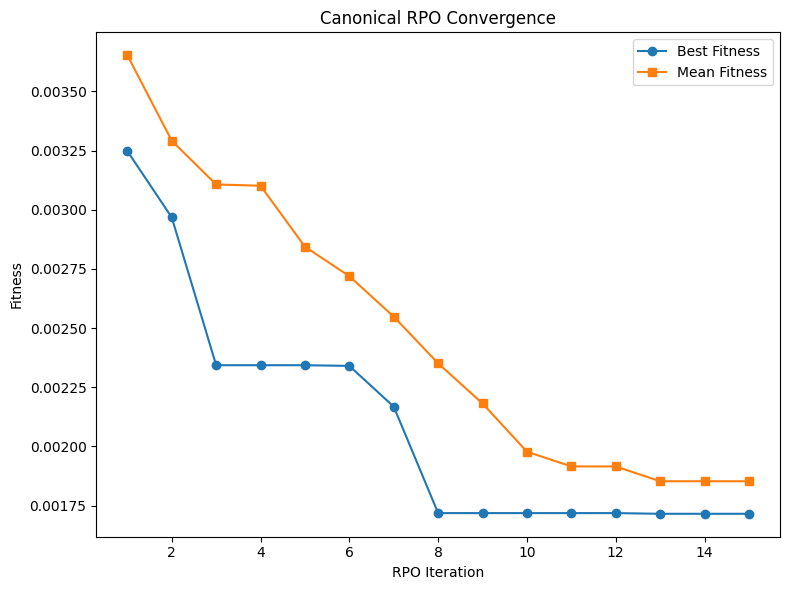

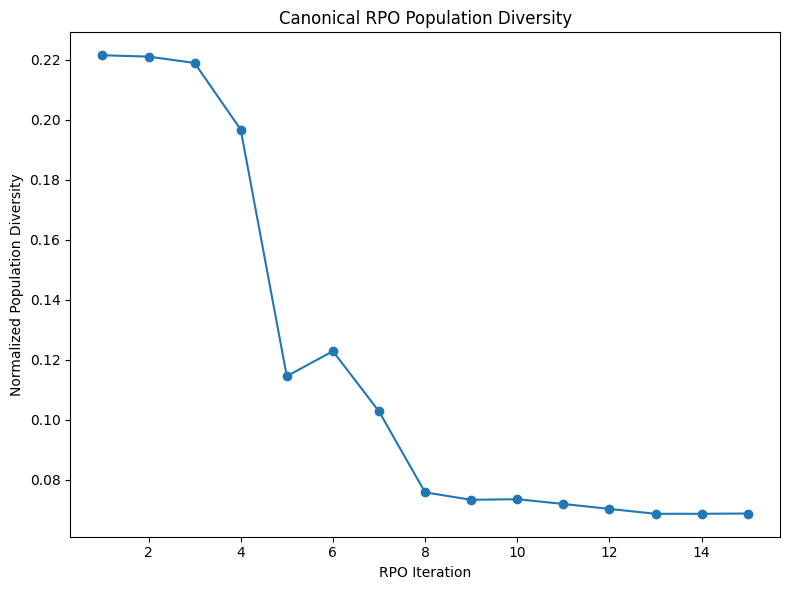

In [ ]:
# ================================================================
# 13. Canonical RPO convergence and diversity plots
# ================================================================
iterations = np.arange(1, len(canonical_rpo_result["Convergence_History"]) + 1)

plt.figure(figsize=(8, 6))
plt.plot(iterations, canonical_rpo_result["Convergence_History"], marker="o", label="Best Fitness")
plt.plot(iterations, canonical_rpo_result["Mean_Fitness_History"], marker="s", label="Mean Fitness")
plt.xlabel("RPO Iteration")
plt.ylabel("Fitness")
plt.title("Canonical RPO Convergence")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "canonical_rpo_convergence.png", dpi=600, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))
plt.plot(iterations, canonical_rpo_result["Diversity_History"], marker="o")
plt.xlabel("RPO Iteration")
plt.ylabel("Normalized Population Diversity")
plt.title("Canonical RPO Population Diversity")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "canonical_rpo_diversity.png", dpi=600, bbox_inches="tight")
plt.show()

In [ ]:
# ================================================================
# 14. Budget-matched Random Search
# ================================================================
def sample_random_rf(rng, random_state=RANDOM_STATE):
    return {
        "n_estimators": int(rng.integers(100, 801)),
        "max_depth": int(rng.integers(3, 31)),
        "min_samples_split": int(rng.integers(2, 21)),
        "min_samples_leaf": int(rng.integers(1, 11)),
        "max_features": round(float(rng.uniform(0.30, 1.00)), 6),
        "class_weight": "balanced" if int(rng.integers(0, 2)) == 1 else None,
        "random_state": int(random_state),
        "n_jobs": -1,
    }

random_objective = RFObjective(
    X_train, y_train, optimization_splits, preprocessor, random_state=RANDOM_STATE
)
rng_rs = np.random.default_rng(RANDOM_STATE + 1000)
rs_start = time.time()

best_rs_fitness = np.inf
best_rs_parameters = None
best_rs_details = None

while random_objective.unique_evaluations < FAIR_OPTIMIZATION_BUDGET:
    params = sample_random_rf(rng_rs, RANDOM_STATE)
    fitness, details = random_objective.evaluate_parameters(params)
    if fitness < best_rs_fitness:
        best_rs_fitness = fitness
        best_rs_parameters = params.copy()
        best_rs_details = details.copy()

random_search_result = {
    "Best_Parameters": best_rs_parameters,
    "Best_Fitness": float(best_rs_fitness),
    "Best_Utility": float(1 - best_rs_fitness),
    "Best_Details": best_rs_details,
    "Unique_Evaluations": int(random_objective.unique_evaluations),
    "Elapsed_Seconds": float(time.time() - rs_start),
}

print(json.dumps(random_search_result, indent=2, default=float))
pd.DataFrame(random_objective.history).to_csv(
    OUTPUT_DIR / "random_search_evaluation_history.csv", index=False
)

{
  "Best_Parameters": {
    "n_estimators": 245,
    "max_depth": 15,
    "min_samples_split": 16,
    "min_samples_leaf": 1,
    "max_features": 0.368648,
    "class_weight": "balanced",
    "random_state": 42,
    "n_jobs": -1
  },
  "Best_Fitness": 0.002165010588399907,
  "Best_Utility": 0.9978349894116001,
  "Best_Details": {
    "Recall": 0.9962616822429906,
    "F1": 0.99812734082397,
    "ROC_AUC": 0.9999269859813085,
    "Balanced_Accuracy": 0.9981308411214953,
    "Utility": 0.9978349894116001,
    "Fitness": 0.002165010588399907
  },
  "Unique_Evaluations": 274,
  "Elapsed_Seconds": 1662.60107088089
}


In [ ]:
# ================================================================
# 16. Budget-matched optimizer development comparison
# ================================================================
optimizer_summary = pd.DataFrame([
    {
        "Method": "Random Search",
        "Best_Development_Utility": random_search_result["Best_Utility"],
        "Best_Development_Fitness": random_search_result["Best_Fitness"],
        "Unique_Evaluations": random_search_result["Unique_Evaluations"],
        "Runtime_sec": random_search_result["Elapsed_Seconds"],
    },
    {
        "Method": "Canonical RPO",
        "Best_Development_Utility": canonical_rpo_result["Best_Utility"],
        "Best_Development_Fitness": canonical_rpo_result["Best_Fitness"],
        "Unique_Evaluations": canonical_rpo_result["Unique_Evaluations"],
        "Runtime_sec": canonical_rpo_result["Elapsed_Seconds"],
    },
]).sort_values("Best_Development_Utility", ascending=False)

optimizer_summary["Absolute_Utility_Difference_vs_Random_Search"] = (
    optimizer_summary["Best_Development_Utility"]
    - float(random_search_result["Best_Utility"])
)

optimizer_summary.to_csv(OUTPUT_DIR / "optimizer_development_summary.csv", index=False)
display(optimizer_summary)


,Method,Best_Development_Utility,Best_Development_Fitness,Unique_Evaluations,Runtime_sec,Absolute_Utility_Difference_vs_Random_Search
1,Canonical RPO,0.998285,0.001715,274,1105.087695,0.00045
0,Random Search,0.997835,0.002165,274,1662.601071,0.00000


In [ ]:
# ================================================================
# 17. RPO stability across random seeds
# ================================================================
if RUN_RPO_MULTI_SEED:
    stability_rows = []

    for seed in RPO_STABILITY_SEEDS:
        print("\nRPO stability seed:", seed)
        splitter = StratifiedKFold(
            n_splits=OPTIMIZATION_CV_SPLITS,
            shuffle=True,
            random_state=seed,
        )
        splits = list(splitter.split(X_train, y_train))
        obj = RFObjective(X_train, y_train, splits, preprocessor, random_state=seed)

        result = canonical_rpo(
            obj,
            population_size=RPO_POPULATION_SIZE,
            maximum_iterations=RPO_ITERATIONS,
            random_state=seed,
            verbose=False,
        )

        stability_rows.append({
            "Seed": seed,
            "Best_Utility": result["Best_Utility"],
            "Best_Fitness": result["Best_Fitness"],
            "Unique_Evaluations": result["Unique_Evaluations"],
            "Runtime_sec": result["Elapsed_Seconds"],
            **{f"Param_{k}": v for k, v in result["Best_Parameters"].items() if k not in ["random_state", "n_jobs"]},
        })
        print(f"Seed {seed}: Utility={result['Best_Utility']:.6f}")

    rpo_stability = pd.DataFrame(stability_rows)
    rpo_stability.to_csv(OUTPUT_DIR / "rpo_multi_seed_stability.csv", index=False)
    display(rpo_stability)

    print("\nRPO utility mean ± SD:",
          f"{rpo_stability['Best_Utility'].mean():.6f} ± {rpo_stability['Best_Utility'].std(ddof=1):.6f}")


RPO stability seed: 11
Seed 11: Utility=0.998905

RPO stability seed: 22
Seed 22: Utility=0.998909

RPO stability seed: 33
Seed 33: Utility=0.998906

RPO stability seed: 44
Seed 44: Utility=0.998910

RPO stability seed: 55
Seed 55: Utility=0.998286


,Seed,Best_Utility,Best_Fitness,Unique_Evaluations,Runtime_sec,Param_n_estimators,Param_max_depth,Param_min_samples_split,Param_min_samples_leaf,Param_max_features,Param_class_weight
0,11,0.998905,0.001095,301,1640.389907,423,7,2,2,0.300000,None
1,22,0.998909,0.001091,301,1169.657068,194,17,6,2,0.383711,balanced
2,33,0.998906,0.001094,297,1263.785249,401,10,4,1,0.379241,balanced
3,44,0.998910,0.001090,287,990.584929,100,7,7,6,0.300000,None
4,55,0.998286,0.001714,267,868.075399,325,3,4,1,0.300000,None



RPO utility mean ± SD: 0.998783 ± 0.000278


## D. Calibration, threshold selection, and locked independent-test evaluation


In [ ]:
# ================================================================
# 18. Calibration + development-only threshold selection helper
# ================================================================
def derive_calibrated_threshold(
    base_model,
    X_dev,
    y_dev,
    random_state=RANDOM_STATE,
):
    outer_cv = StratifiedKFold(
        n_splits=5, shuffle=True, random_state=random_state + 500
    )
    calibrator = make_calibrator(
        clone(base_model), cv=CALIBRATION_INNER_CV, method="sigmoid"
    )

    oof_prob = cross_val_predict(
        calibrator,
        X_dev,
        y_dev,
        cv=outer_cv,
        method="predict_proba",
        n_jobs=1,
    )[:, 1]

    rows = []
    for threshold in THRESHOLD_GRID:
        m = threshold_metrics(y_dev, oof_prob, threshold)
        rows.append({
            "Threshold": threshold,
            "Sensitivity": m["Sensitivity"],
            "Specificity": m["Specificity"],
            "F1": m["F1"],
            "Balanced_Accuracy": m["Balanced_Accuracy"],
        })

    table = pd.DataFrame(rows)
    eligible = table[table["Sensitivity"] >= MINIMUM_SENSITIVITY].copy()

    if len(eligible):
        chosen = eligible.sort_values(
            ["F1", "Specificity", "Balanced_Accuracy"],
            ascending=False,
        ).iloc[0]
    else:
        chosen = table.sort_values(
            ["Balanced_Accuracy", "F1"], ascending=False
        ).iloc[0]

    return {
        "Threshold": float(chosen["Threshold"]),
        "Eligible_Count": int(len(eligible)),
        "OOF_Probabilities": oof_prob,
        "Threshold_Table": table,
    }

def evaluate_locked_model_on_test(
    model_name,
    base_model,
    X_dev,
    y_dev,
    X_holdout,
    y_holdout,
    random_state=RANDOM_STATE,
):
    threshold_info = derive_calibrated_threshold(
        base_model, X_dev, y_dev, random_state=random_state
    )

    final_calibrator = make_calibrator(
        clone(base_model), cv=FINAL_CALIBRATION_CV, method="sigmoid"
    )
    final_calibrator.fit(X_dev, y_dev)

    test_prob = final_calibrator.predict_proba(X_holdout)[:, 1]
    threshold = threshold_info["Threshold"]
    test_pred = (test_prob >= threshold).astype(int)

    cls = threshold_metrics(y_holdout, test_prob, threshold)
    prob = probability_metrics(y_holdout, test_prob)
    metrics = {**cls, **prob}
    metrics["Utility"] = compute_utility(
        metrics["Sensitivity"], metrics["F1"],
        metrics["ROC_AUC"], metrics["Balanced_Accuracy"]
    )
    metrics["Model"] = model_name
    metrics["Eligible_Threshold_Count"] = threshold_info["Eligible_Count"]

    return {
        "Metrics": metrics,
        "Probabilities": test_prob,
        "Predictions": test_pred,
        "Threshold_Info": threshold_info,
        "Fitted_Calibrator": final_calibrator,
    }

print("Calibration/threshold helpers ready.")

Calibration/threshold helpers ready.


Eligible thresholds with sensitivity >= 0.90: 91
Selected threshold: 0.52


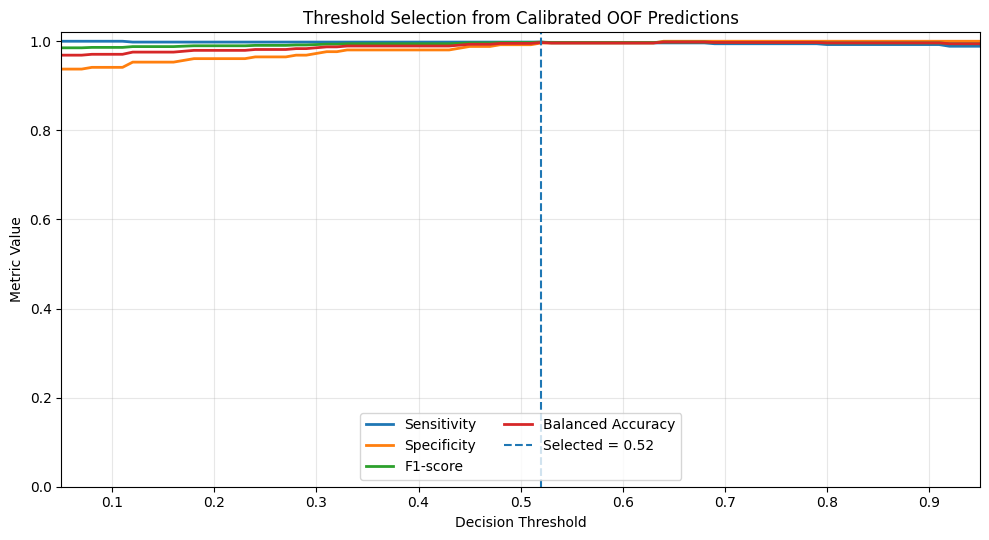

In [ ]:
# ================================================================
# 19. Development-only calibrated OOF threshold selection (Figure 6)
# ================================================================
canonical_model = make_rf_pipeline(CANONICAL_RF_PARAMS)

canonical_threshold_info = derive_calibrated_threshold(
    canonical_model,
    X_train,
    y_train,
    random_state=RANDOM_STATE,
)

threshold_df = canonical_threshold_info["Threshold_Table"].copy()
selected_threshold = canonical_threshold_info["Threshold"]

print("Eligible thresholds with sensitivity >= 0.90:",
      canonical_threshold_info["Eligible_Count"])
print(f"Selected threshold: {selected_threshold:.2f}")

plt.figure(figsize=(10, 5.5))
plt.plot(threshold_df["Threshold"], threshold_df["Sensitivity"], label="Sensitivity", linewidth=2)
plt.plot(threshold_df["Threshold"], threshold_df["Specificity"], label="Specificity", linewidth=2)
plt.plot(threshold_df["Threshold"], threshold_df["F1"], label="F1-score", linewidth=2)
plt.plot(threshold_df["Threshold"], threshold_df["Balanced_Accuracy"], label="Balanced Accuracy", linewidth=2)
plt.axvline(selected_threshold, linestyle="--", linewidth=1.5,
            label=f"Selected = {selected_threshold:.2f}")
plt.xlabel("Decision Threshold")
plt.ylabel("Metric Value")
plt.title("Threshold Selection from Calibrated OOF Predictions")
plt.ylim(0, 1.02)
plt.xlim(0.05, 0.95)
plt.grid(alpha=0.3)
plt.legend(loc="lower center", ncol=2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_6_Threshold_Selection.png", dpi=600, bbox_inches="tight")
plt.show()

threshold_df.to_csv(OUTPUT_DIR / "canonical_threshold_analysis.csv", index=False)


In [ ]:
# ================================================================
# 20. Locked independent-test benchmarking
# ================================================================
baseline_rf_params = {
    "n_estimators": 100,
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "class_weight": "balanced",
    "random_state": RANDOM_STATE,
    "n_jobs": -1,
}

locked_models = {
    "Baseline RF": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(**baseline_rf_params)),
    ]),
    "Random Search RF": make_rf_pipeline(random_search_result["Best_Parameters"]),
    "Canonical RPO RF": make_rf_pipeline(CANONICAL_RF_PARAMS),
}

locked_results = {}

for name, model in locked_models.items():
    print("\nEvaluating locked model:", name)
    locked_results[name] = evaluate_locked_model_on_test(
        name, model,
        X_train, y_train,
        X_test, y_test,
        random_state=RANDOM_STATE,
    )
    locked_results[name]["Threshold_Info"]["Threshold_Table"].to_csv(
        OUTPUT_DIR / f"threshold_analysis_{name.replace(' ', '_')}.csv",
        index=False
    )

final_test_table = pd.DataFrame(
    [result["Metrics"] for result in locked_results.values()]
).set_index("Model")

final_test_table.to_csv(OUTPUT_DIR / "prespecified_independent_test_comparison.csv")
display(final_test_table)

print(
    "\nImportant: all development decisions were completed without using the locked test set."
)



Evaluating locked model: Baseline RF

Evaluating locked model: Random Search RF

Evaluating locked model: Canonical RPO RF


,Threshold,Accuracy,Balanced_Accuracy,Precision,Sensitivity,Specificity,NPV,F1,MCC,Cohen_Kappa,TN,FP,FN,TP,ROC_AUC,PR_AUC,Brier,Log_Loss,Utility,Eligible_Threshold_Count
Model,,,,,,,,,,,,,,,,,,,,
Baseline RF,0.50,0.994949,0.996269,1.0,0.992537,1.0,0.984615,0.996255,0.988568,0.988503,64,0,1,133,1.0,1.0,0.002340,0.019175,0.995705,91
Random Search RF,0.51,0.994949,0.996269,1.0,0.992537,1.0,0.984615,0.996255,0.988568,0.988503,64,0,1,133,1.0,1.0,0.002512,0.019317,0.995705,91
Canonical RPO RF,0.52,0.994949,0.996269,1.0,0.992537,1.0,0.984615,0.996255,0.988568,0.988503,64,0,1,133,1.0,1.0,0.002887,0.021301,0.995705,91



Important: all development decisions were completed without using the locked test set.


Threshold   : 0.52
ROC-AUC     : 1.000000
PR-AUC      : 1.000000
Brier Score : 0.002887
Log Loss    : 0.021301


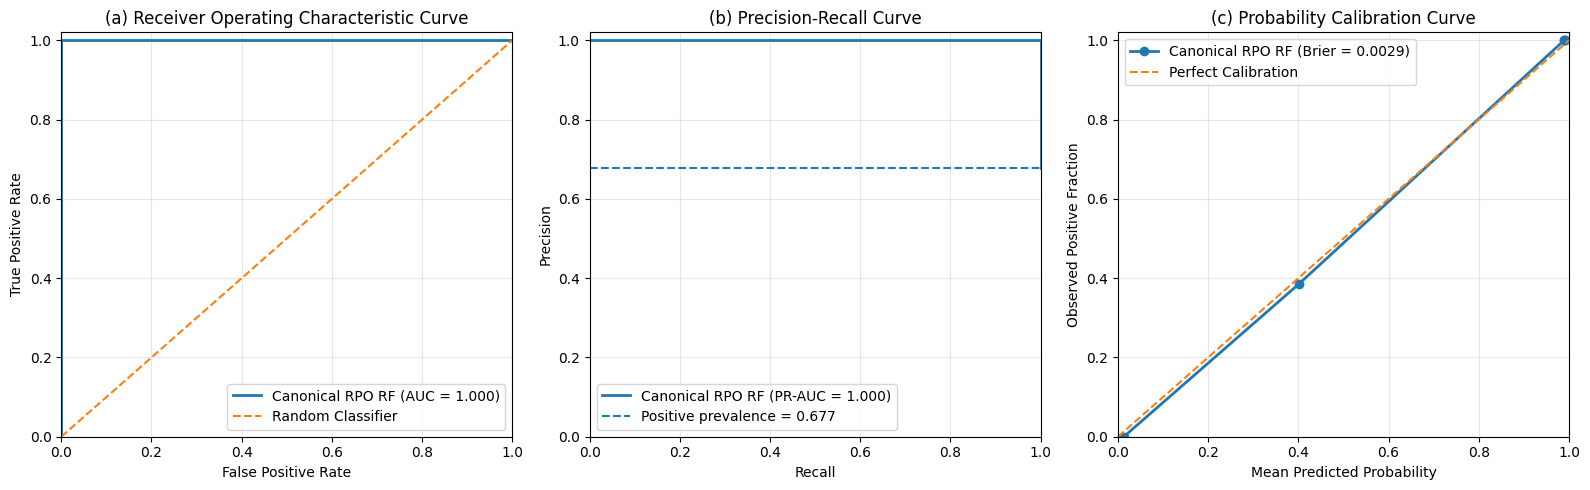

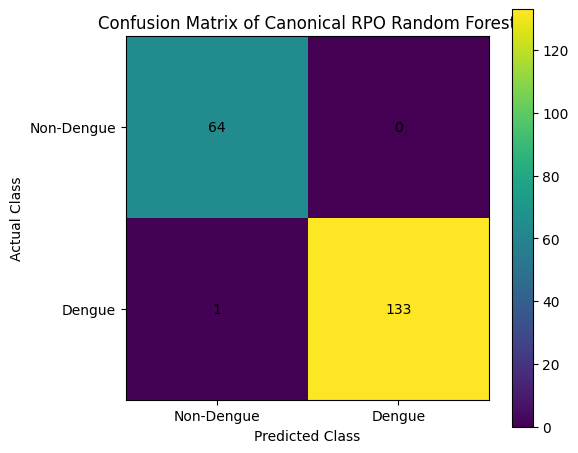

In [ ]:
# ================================================================
# 21. Final discrimination/calibration and confusion matrix
#     Figures 5 and 7
# ================================================================
canonical_result = locked_results["Canonical RPO RF"]
y_true = np.asarray(y_test)
rpo_prob = np.asarray(canonical_result["Probabilities"])
rpo_pred = np.asarray(canonical_result["Predictions"])
rpo_threshold = canonical_result["Metrics"]["Threshold"]

roc_auc = roc_auc_score(y_true, rpo_prob)
pr_auc = average_precision_score(y_true, rpo_prob)
brier = brier_score_loss(y_true, rpo_prob)
logloss = log_loss(y_true, rpo_prob, labels=[0, 1])

fpr, tpr, _ = roc_curve(y_true, rpo_prob)
precision_curve, recall_curve, _ = precision_recall_curve(y_true, rpo_prob)

fraction_positive, mean_predicted_probability = calibration_curve(
    y_true, rpo_prob, n_bins=5, strategy="quantile"
)

print(f"Threshold   : {rpo_threshold:.2f}")
print(f"ROC-AUC     : {roc_auc:.6f}")
print(f"PR-AUC      : {pr_auc:.6f}")
print(f"Brier Score : {brier:.6f}")
print(f"Log Loss    : {logloss:.6f}")

# Figure 5
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].plot(fpr, tpr, linewidth=2, label=f"Canonical RPO RF (AUC = {roc_auc:.3f})")
axes[0].plot([0,1],[0,1],"--",linewidth=1.5,label="Random Classifier")
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate",
            title="(a) Receiver Operating Characteristic Curve", xlim=(0,1), ylim=(0,1.02))
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

axes[1].plot(recall_curve, precision_curve, linewidth=2,
             label=f"Canonical RPO RF (PR-AUC = {pr_auc:.3f})")
axes[1].axhline(y_true.mean(), linestyle="--", linewidth=1.5,
                label=f"Positive prevalence = {y_true.mean():.3f}")
axes[1].set(xlabel="Recall", ylabel="Precision",
            title="(b) Precision-Recall Curve", xlim=(0,1), ylim=(0,1.02))
axes[1].legend(loc="lower left"); axes[1].grid(alpha=0.3)

axes[2].plot(mean_predicted_probability, fraction_positive, marker="o", linewidth=2,
             label=f"Canonical RPO RF (Brier = {brier:.4f})")
axes[2].plot([0,1],[0,1],"--",linewidth=1.5,label="Perfect Calibration")
axes[2].set(xlabel="Mean Predicted Probability", ylabel="Observed Positive Fraction",
            title="(c) Probability Calibration Curve", xlim=(0,1), ylim=(0,1.02))
axes[2].legend(loc="upper left"); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_5_Canonical_RPO_Discrimination_Calibration.png",
            dpi=600, bbox_inches="tight")
plt.show()

# Figure 7
cm = confusion_matrix(y_true, rpo_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.title("Confusion Matrix of Canonical RPO Random Forest")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks([0,1], ["Non-Dengue","Dengue"])
plt.yticks([0,1], ["Non-Dengue","Dengue"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i,j]), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_7_Confusion_Matrix.png", dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
# ================================================================
# 19. Calibration diagnostics: intercept, slope, ECE, Spiegelhalter Z
# ================================================================
def calibration_intercept_slope(y_true, prob):
    y_arr = np.asarray(y_true, dtype=float)
    p = np.clip(np.asarray(prob, dtype=float), 1e-6, 1 - 1e-6)
    logit_p = np.log(p / (1 - p))

    try:
        X_design = sm.add_constant(logit_p)
        model = sm.GLM(y_arr, X_design, family=sm.families.Binomial()).fit()
        intercept = float(model.params[0])
        slope = float(model.params[1])
    except Exception:
        intercept, slope = np.nan, np.nan

    return intercept, slope

def expected_calibration_error(y_true, prob, n_bins=10):
    y_arr = np.asarray(y_true, dtype=float)
    p = np.asarray(prob, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for left, right in zip(edges[:-1], edges[1:]):
        if right == 1:
            mask = (p >= left) & (p <= right)
        else:
            mask = (p >= left) & (p < right)
        if mask.sum() == 0:
            continue
        ece += (mask.mean()) * abs(y_arr[mask].mean() - p[mask].mean())

    return float(ece)

def spiegelhalter_z_test(y_true, prob):
    y_arr = np.asarray(y_true, dtype=float)
    p = np.clip(np.asarray(prob, dtype=float), 1e-8, 1 - 1e-8)

    numerator = np.sum((y_arr - p) * (1 - 2 * p))
    variance = np.sum(((1 - 2 * p) ** 2) * p * (1 - p))

    if variance <= 0:
        return np.nan, np.nan

    z = numerator / np.sqrt(variance)
    p_value = 2 * (1 - norm.cdf(abs(z)))
    return float(z), float(p_value)

calibration_rows = []

for name in ["Canonical RPO RF"]:
    result = locked_results[name]
    prob = result["Probabilities"]
    intercept, slope = calibration_intercept_slope(y_test, prob)
    z, z_p = spiegelhalter_z_test(y_test, prob)

    calibration_rows.append({
        "Model": name,
        "Brier": brier_score_loss(y_test, prob),
        "Log_Loss": log_loss(y_test, prob, labels=[0, 1]),
        "Calibration_Intercept": intercept,
        "Calibration_Slope": slope,
        "ECE_10bins": expected_calibration_error(y_test, prob, 10),
        "Spiegelhalter_Z": z,
        "Spiegelhalter_P": z_p,
    })

calibration_table = pd.DataFrame(calibration_rows)
calibration_table.to_csv(OUTPUT_DIR / "calibration_diagnostics_canonical_rpo.csv", index=False)
display(calibration_table)

print("Note: calibration intercept/slope can be unstable under near-perfect separation.")


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1269: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  return self._fit_irls(


,Model,Brier,Log_Loss,Calibration_Intercept,Calibration_Slope,ECE_10bins,Spiegelhalter_Z,Spiegelhalter_P
0,Canonical RPO RF,0.002887,0.021301,44.032616,138.630726,0.019215,-1.721008,0.085249


Note: calibration intercept/slope can be unstable under near-perfect separation.


## E. Reviewer robustness and uncertainty analyses


,Prevalence,PPV,NPV
0,0.05,1.0,0.999607
1,0.10,1.0,0.999171
2,0.15,1.0,0.998685
3,0.20,1.0,0.998138
4,0.25,1.0,0.997519
5,0.30,1.0,0.996812
6,0.35,1.0,0.995998
7,0.40,1.0,0.995050
8,0.45,1.0,0.993931
9,0.50,1.0,0.992593


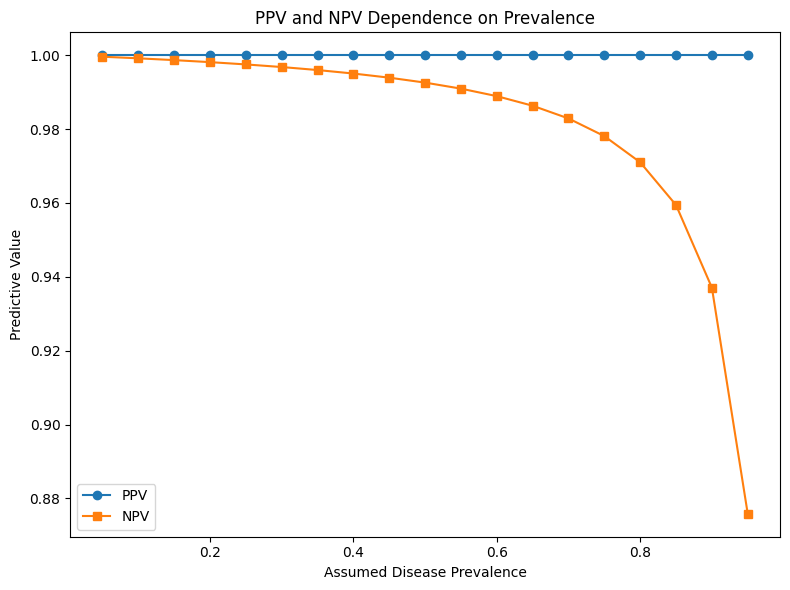

In [ ]:
# ================================================================
# 23. PPV / NPV sensitivity to assumed prevalence (Figure 8)
# ================================================================
canonical_metrics = locked_results["Canonical RPO RF"]["Metrics"]
sens = canonical_metrics["Sensitivity"]
spec = canonical_metrics["Specificity"]

prevalence_grid = np.arange(0.05, 0.951, 0.05)
prevalence_rows = []

for prev in prevalence_grid:
    ppv = (sens * prev) / (sens * prev + (1 - spec) * (1 - prev))
    npv = (spec * (1 - prev)) / ((1 - sens) * prev + spec * (1 - prev))
    prevalence_rows.append({"Prevalence": prev, "PPV": ppv, "NPV": npv})

prevalence_df = pd.DataFrame(prevalence_rows)
prevalence_df.to_csv(OUTPUT_DIR / "ppv_npv_prevalence_sensitivity.csv", index=False)
display(prevalence_df)

plt.figure(figsize=(8, 6))
plt.plot(prevalence_df["Prevalence"], prevalence_df["PPV"], marker="o", label="PPV")
plt.plot(prevalence_df["Prevalence"], prevalence_df["NPV"], marker="s", label="NPV")
plt.xlabel("Assumed Disease Prevalence")
plt.ylabel("Predictive Value")
plt.title("PPV and NPV Dependence on Prevalence")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_8_PPV_NPV_vs_Prevalence.png", dpi=600, bbox_inches="tight")
plt.show()


Sensitivity: 0.99254
Specificity: 1.0

Prevalence-sensitive predictive values with uncertainty:


,Prevalence,PPV_Point,PPV_Median,PPV_Lower_95CrI,PPV_Upper_95CrI,NPV_Point,NPV_Median,NPV_Lower_95CrI,NPV_Upper_95CrI
0,0.05,1.0,0.93751,0.57606,0.99985,0.99961,0.99953,0.99818,0.99996
1,0.10,1.0,0.96939,0.74151,0.99993,0.99917,0.99901,0.99617,0.99991
2,0.15,1.0,0.98051,0.82002,0.99995,0.99868,0.99844,0.99393,0.99986
3,0.20,1.0,0.98616,0.86585,0.99997,0.99814,0.99778,0.99142,0.99980
4,0.25,1.0,0.98958,0.89590,0.99998,0.99752,0.99705,0.98859,0.99973
5,0.30,1.0,0.99188,0.91711,0.99998,0.99681,0.99621,0.98538,0.99965
6,0.35,1.0,0.99353,0.93290,0.99998,0.99600,0.99524,0.98170,0.99956
7,0.40,1.0,0.99477,0.94509,0.99999,0.99505,0.99411,0.97745,0.99946
8,0.45,1.0,0.99573,0.95480,0.99999,0.99393,0.99279,0.97246,0.99933
9,0.50,1.0,0.99650,0.96271,0.99999,0.99259,0.99120,0.96655,0.99918


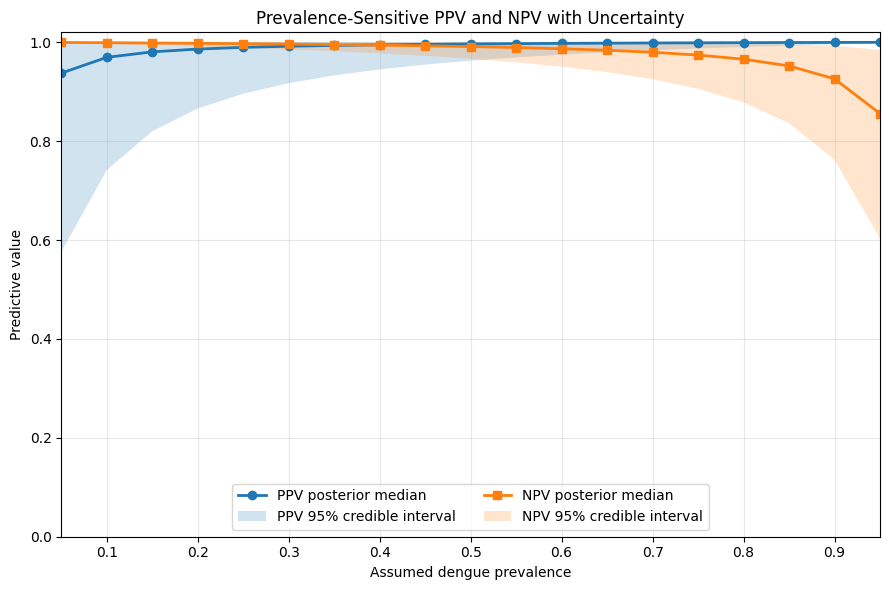


Figure saved as:
 - Figure_8_PPV_NPV_Uncertainty.png
 - Figure_8_PPV_NPV_Uncertainty.pdf
 - Figure8_prevalence_uncertainty_results.csv


In [ ]:
# ============================================================
# FIGURE 8 - PREVALENCE-SENSITIVE PPV AND NPV WITH UNCERTAINTY
# Based on the final independent-test confusion matrix
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Final independent test-set confusion matrix
TP = 133
FN = 1
TN = 64
FP = 0

# Point estimates
sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print("Sensitivity:", round(sensitivity, 5))
print("Specificity:", round(specificity, 5))

# Monte Carlo settings
n_draws = 50000
rng = np.random.default_rng(42)

# Jeffreys-prior posterior draws
# Sensitivity ~ Beta(TP + 0.5, FN + 0.5)
# Specificity ~ Beta(TN + 0.5, FP + 0.5)
sens_draws = rng.beta(TP + 0.5, FN + 0.5, n_draws)
spec_draws = rng.beta(TN + 0.5, FP + 0.5, n_draws)

# Assumed prevalence values
prevalences = np.arange(0.05, 0.951, 0.05)

results = []

for p in prevalences:
    # Posterior draws for PPV and NPV
    ppv_draws = (sens_draws * p) / (
        sens_draws * p + (1 - spec_draws) * (1 - p)
    )

    npv_draws = (spec_draws * (1 - p)) / (
        spec_draws * (1 - p) + (1 - sens_draws) * p
    )

    # Posterior summaries
    ppv_lower, ppv_median, ppv_upper = np.quantile(ppv_draws, [0.025, 0.5, 0.975])
    npv_lower, npv_median, npv_upper = np.quantile(npv_draws, [0.025, 0.5, 0.975])

    # Original point estimates
    ppv_point = (sensitivity * p) / (
        sensitivity * p + (1 - specificity) * (1 - p)
    )

    npv_point = (specificity * (1 - p)) / (
        specificity * (1 - p) + (1 - sensitivity) * p
    )

    results.append({
        "Prevalence": p,
        "PPV_Point": ppv_point,
        "PPV_Median": ppv_median,
        "PPV_Lower_95CrI": ppv_lower,
        "PPV_Upper_95CrI": ppv_upper,
        "NPV_Point": npv_point,
        "NPV_Median": npv_median,
        "NPV_Lower_95CrI": npv_lower,
        "NPV_Upper_95CrI": npv_upper
    })

# Results table
df_prev = pd.DataFrame(results)

print("\nPrevalence-sensitive predictive values with uncertainty:")
display(df_prev.round(5))

# Save the table if needed
df_prev.to_csv("Figure8_prevalence_uncertainty_results.csv", index=False)

# -----------------------------
# Plot Figure 8
# -----------------------------
plt.figure(figsize=(9, 6))

# PPV median line
plt.plot(
    df_prev["Prevalence"],
    df_prev["PPV_Median"],
    marker="o",
    linewidth=2,
    label="PPV posterior median"
)

# PPV credible interval band
plt.fill_between(
    df_prev["Prevalence"],
    df_prev["PPV_Lower_95CrI"],
    df_prev["PPV_Upper_95CrI"],
    alpha=0.20,
    label="PPV 95% credible interval"
)

# NPV median line
plt.plot(
    df_prev["Prevalence"],
    df_prev["NPV_Median"],
    marker="s",
    linewidth=2,
    label="NPV posterior median"
)

# NPV credible interval band
plt.fill_between(
    df_prev["Prevalence"],
    df_prev["NPV_Lower_95CrI"],
    df_prev["NPV_Upper_95CrI"],
    alpha=0.20,
    label="NPV 95% credible interval"
)

plt.xlabel("Assumed dengue prevalence")
plt.ylabel("Predictive value")
plt.title("Prevalence-Sensitive PPV and NPV with Uncertainty")
plt.xlim(0.05, 0.95)
plt.ylim(0.0, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower center", ncol=2)
plt.tight_layout()

# Save figure
plt.savefig("Figure_8_PPV_NPV_Uncertainty.png", dpi=400, bbox_inches="tight")
plt.savefig("Figure_8_PPV_NPV_Uncertainty.pdf", bbox_inches="tight")

plt.show()

print("\nFigure saved as:")
print(" - Figure_8_PPV_NPV_Uncertainty.png")
print(" - Figure_8_PPV_NPV_Uncertainty.pdf")
print(" - Figure8_prevalence_uncertainty_results.csv")

,Metric,Point_Estimate,Bootstrap_Mean,CI_2.5,CI_97.5,Model
0,Accuracy,0.994949,0.994924,0.984848,1.000000,Canonical RPO RF
1,Balanced_Accuracy,0.996269,0.996247,0.987603,1.000000,Canonical RPO RF
2,Precision,1.000000,1.000000,1.000000,1.000000,Canonical RPO RF
3,Sensitivity,0.992537,0.992494,0.975207,1.000000,Canonical RPO RF
4,Specificity,1.000000,1.000000,1.000000,1.000000,Canonical RPO RF
5,NPV,0.984615,0.984579,0.947368,1.000000,Canonical RPO RF
6,F1,0.996255,0.996218,0.987448,1.000000,Canonical RPO RF
7,ROC_AUC,1.000000,1.000000,1.000000,1.000000,Canonical RPO RF
8,PR_AUC,1.000000,1.000000,1.000000,1.000000,Canonical RPO RF
9,MCC,0.988568,0.988520,0.962729,1.000000,Canonical RPO RF


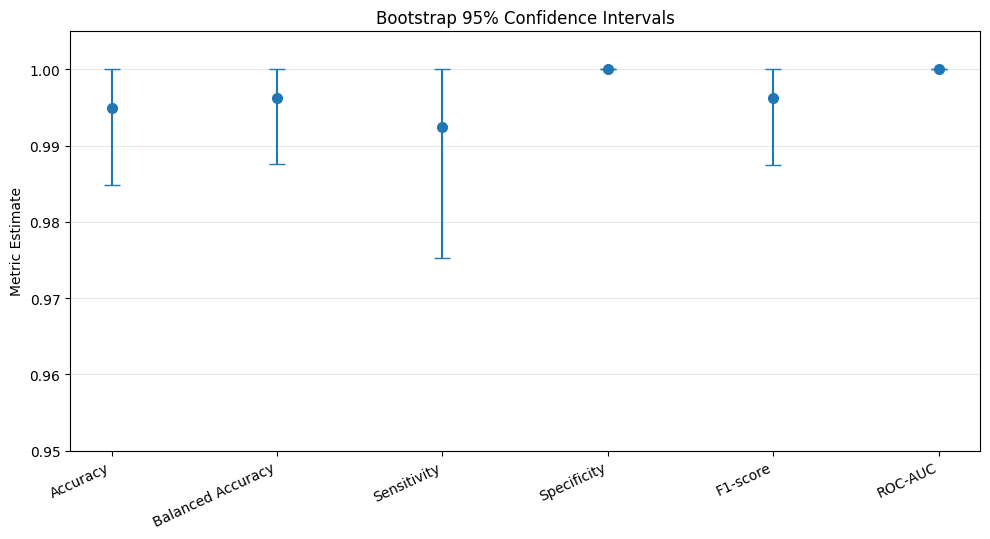

In [ ]:
# ================================================================
# 20. Bootstrap confidence intervals on the independent test set
# ================================================================
def metric_bundle(y_true, prob, threshold):
    cls = threshold_metrics(y_true, prob, threshold)
    prob_m = probability_metrics(y_true, prob)
    return {
        "Accuracy": cls["Accuracy"],
        "Balanced_Accuracy": cls["Balanced_Accuracy"],
        "Precision": cls["Precision"],
        "Sensitivity": cls["Sensitivity"],
        "Specificity": cls["Specificity"],
        "NPV": cls["NPV"],
        "F1": cls["F1"],
        "ROC_AUC": prob_m["ROC_AUC"],
        "PR_AUC": prob_m["PR_AUC"],
        "MCC": cls["MCC"],
        "Cohen_Kappa": cls["Cohen_Kappa"],
        "Brier": prob_m["Brier"],
        "Log_Loss": prob_m["Log_Loss"],
    }

def bootstrap_ci(y_true, prob, threshold, n_boot=BOOTSTRAP_REPLICATES, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_arr = np.asarray(y_true, dtype=int)
    p_arr = np.asarray(prob, dtype=float)
    n = len(y_arr)
    rows = []

    attempts = 0
    while len(rows) < n_boot and attempts < n_boot * 5:
        attempts += 1
        idx = rng.integers(0, n, size=n)
        yb = y_arr[idx]
        pb = p_arr[idx]
        if len(np.unique(yb)) < 2:
            continue
        try:
            rows.append(metric_bundle(yb, pb, threshold))
        except Exception:
            continue

    boot = pd.DataFrame(rows)
    summary = []
    point = metric_bundle(y_arr, p_arr, threshold)

    for metric in boot.columns:
        summary.append({
            "Metric": metric,
            "Point_Estimate": point[metric],
            "Bootstrap_Mean": float(boot[metric].mean()),
            "CI_2.5": float(boot[metric].quantile(0.025)),
            "CI_97.5": float(boot[metric].quantile(0.975)),
        })

    return pd.DataFrame(summary), boot

# Canonical RPO only, matching the manuscript.
canonical_result = locked_results["Canonical RPO RF"]
canonical_threshold = canonical_result["Metrics"]["Threshold"]

canonical_bootstrap_summary, canonical_bootstrap_distribution = bootstrap_ci(
    y_test,
    canonical_result["Probabilities"],
    canonical_threshold,
    n_boot=BOOTSTRAP_REPLICATES,
    seed=BOOTSTRAP_SEED,
)

canonical_bootstrap_summary["Model"] = "Canonical RPO RF"
canonical_bootstrap_summary.to_csv(
    OUTPUT_DIR / "bootstrap_confidence_intervals_canonical_rpo.csv", index=False
)
canonical_bootstrap_distribution.to_csv(
    OUTPUT_DIR / "bootstrap_distribution_canonical_rpo.csv", index=False
)
display(canonical_bootstrap_summary)

# Figure 9
plot_metrics = ["Accuracy", "Balanced_Accuracy", "Sensitivity", "Specificity", "F1", "ROC_AUC"]
plot_df = canonical_bootstrap_summary[
    canonical_bootstrap_summary["Metric"].isin(plot_metrics)
].set_index("Metric").loc[plot_metrics]

means = plot_df["Bootstrap_Mean"].to_numpy()
lower = plot_df["CI_2.5"].to_numpy()
upper = plot_df["CI_97.5"].to_numpy()
errors = np.vstack([means-lower, upper-means])

x = np.arange(len(plot_metrics))
labels = ["Accuracy", "Balanced Accuracy", "Sensitivity", "Specificity", "F1-score", "ROC-AUC"]

plt.figure(figsize=(10, 5.5))
plt.errorbar(x, means, yerr=errors, fmt="o", capsize=6, markersize=7, linewidth=1.5)
plt.xticks(x, labels, rotation=25, ha="right")
plt.ylabel("Metric Estimate")
plt.title("Bootstrap 95% Confidence Intervals")
plt.ylim(0.95, 1.005)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Figure_9_Bootstrap_Confidence_Intervals.png",
            dpi=600, bbox_inches="tight")
plt.show()


In [ ]:
# ================================================================
# 25. Median vs KNN imputation sensitivity
# ================================================================
if RUN_IMPUTATION_SENSITIVITY:
    final_params = CANONICAL_RF_PARAMS.copy()
    sensitivity_splits = baseline_splits

    imputation_rows = []

    for method in ["median", "knn"]:
        prep = build_preprocessor(method)
        model = make_rf_pipeline(final_params, prep=prep)

        cv_result = cross_validate(
            model, X_train, y_train,
            cv=sensitivity_splits,
            scoring={
                "Balanced_Accuracy": "balanced_accuracy",
                "Recall": "recall",
                "F1": "f1",
                "ROC_AUC": "roc_auc",
                "PR_AUC": "average_precision",
            },
            n_jobs=1,
        )

        for fold_id in range(len(sensitivity_splits)):
            imputation_rows.append({
                "Imputation": method,
                "Fold_ID": fold_id,
                "Balanced_Accuracy": cv_result["test_Balanced_Accuracy"][fold_id],
                "Recall": cv_result["test_Recall"][fold_id],
                "F1": cv_result["test_F1"][fold_id],
                "ROC_AUC": cv_result["test_ROC_AUC"][fold_id],
                "PR_AUC": cv_result["test_PR_AUC"][fold_id],
            })

    imputation_df = pd.DataFrame(imputation_rows)
    imputation_df.to_csv(OUTPUT_DIR / "imputation_sensitivity_folds.csv", index=False)

    imp_summary = imputation_df.groupby("Imputation").agg(["mean", "std"])
    display(imp_summary)

    # Paired Wilcoxon on same folds
    imp_tests = []
    med = imputation_df[imputation_df["Imputation"] == "median"].sort_values("Fold_ID")
    knn = imputation_df[imputation_df["Imputation"] == "knn"].sort_values("Fold_ID")
    for metric in ["Balanced_Accuracy", "Recall", "F1", "ROC_AUC", "PR_AUC"]:
        stat, p = wilcoxon(med[metric], knn[metric], zero_method="wilcox")
        imp_tests.append({"Metric": metric, "Wilcoxon_Statistic": stat, "P": p})
    pd.DataFrame(imp_tests).to_csv(OUTPUT_DIR / "imputation_sensitivity_tests.csv", index=False)
    display(pd.DataFrame(imp_tests))


Fold_ID           Balanced_Accuracy              Recall            \
              mean       std              mean       std      mean       std   
Imputation                                                                     
knn           12.0  7.359801          0.995767  0.005456  0.997009  0.005204   
median        12.0  7.359801          0.996133  0.005618  0.997757  0.004886   

                  F1             ROC_AUC              PR_AUC            
                mean       std      mean       std      mean       std  
Imputation                                                              
knn         0.997194  0.003575  0.999941  0.000102  0.999972  0.000048  
median      0.997571  0.003337  0.999905  0.000206  0.999956  0.000095

,Metric,Wilcoxon_Statistic,P
0,Balanced_Accuracy,41.5,0.778840
1,Recall,13.5,0.479500
2,F1,39.0,0.648440
3,ROC_AUC,11.5,0.361547
4,PR_AUC,9.0,0.397180


## F. Global explainability


,Feature,Mean_Absolute_SHAP
2,WBC Count,0.207917
3,Platelet Count,0.151310
4,PDW,0.044675
0,Age,0.008334
6,RBC PANEL,0.003220
1,Haemoglobin,0.002172
5,Differential Count,0.001932
9,Sex Male,0.000522
8,Sex Female,0.000243
7,Sex Child,0.000162


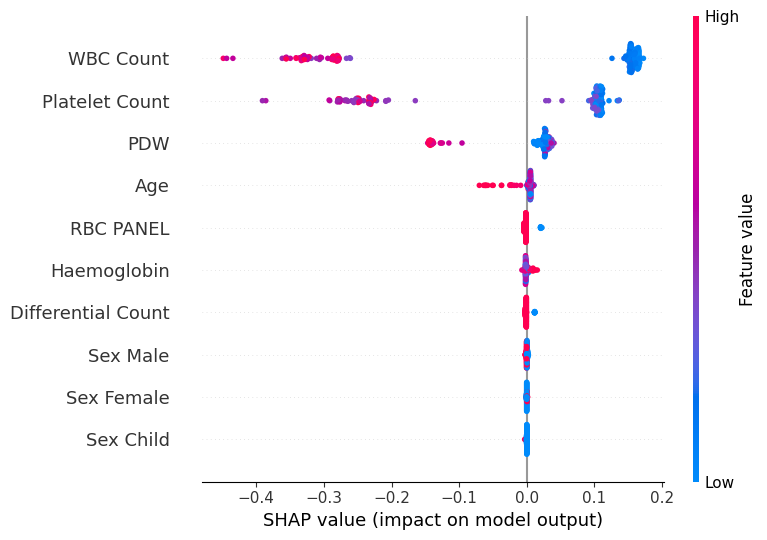

SHAP explains the underlying canonical Random Forest output, not the calibrated probabilities and not clinical causation.


In [ ]:
# ================================================================
# 26. Global SHAP analysis for the canonical RPO Random Forest
#     Figure 10
# ================================================================
if RUN_SHAP:
    import shap

    final_uncalibrated = make_rf_pipeline(CANONICAL_RF_PARAMS)
    final_uncalibrated.fit(X_train, y_train)

    fitted_preprocessor = final_uncalibrated.named_steps["preprocessor"]
    fitted_rf = final_uncalibrated.named_steps["classifier"]
    X_test_transformed = fitted_preprocessor.transform(X_test)

    try:
        raw_feature_names = list(fitted_preprocessor.get_feature_names_out())
    except Exception:
        raw_feature_names = [f"Feature_{i}" for i in range(X_test_transformed.shape[1])]

    def clean_feature_name(name):
        for prefix in ("continuous__", "binary__", "categorical__"):
            if name.startswith(prefix):
                name = name[len(prefix):]
        return name.replace("Sex_", "Sex ")

    feature_names = [clean_feature_name(x) for x in raw_feature_names]

    explainer = shap.TreeExplainer(fitted_rf)
    shap_values = explainer.shap_values(X_test_transformed)

    if isinstance(shap_values, list):
        sv = shap_values[1] if len(shap_values) > 1 else shap_values[0]
    else:
        sv = np.asarray(shap_values)
        if sv.ndim == 3:
            sv = sv[:, :, 1]

    mean_abs = np.mean(np.abs(sv), axis=0)
    shap_importance = pd.DataFrame({
        "Feature": feature_names,
        "Mean_Absolute_SHAP": mean_abs,
    }).sort_values("Mean_Absolute_SHAP", ascending=False)

    shap_importance.to_csv(OUTPUT_DIR / "global_shap_importance_canonical_rpo.csv", index=False)
    display(shap_importance)

    shap.summary_plot(
        sv,
        X_test_transformed,
        feature_names=feature_names,
        show=False,
    )
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "Figure_10_Global_SHAP_Summary.png", dpi=600, bbox_inches="tight")
    plt.show()

    print(
        "SHAP explains the underlying canonical Random Forest output, "
        "not the calibrated probabilities and not clinical causation."
    )


## G. Canonical manuscript export


In [ ]:
# ================================================================
# 27. Canonical manuscript result export
# ================================================================
canonical_export = {
    "Dataset": {
        "Original_Rows": int(len(raw_df)),
        "Labelled_Rows": int(len(df)),
        "Positive": int((y == 1).sum()),
        "Negative": int((y == 0).sum()),
        "Development_Rows": int(len(X_train)),
        "Test_Rows": int(len(X_test)),
    },
    "Utility_Weights": UTILITY_WEIGHTS,
    "Fair_Optimization_Budget_Unique_Evaluations": int(FAIR_OPTIMIZATION_BUDGET),
    "Optimizer_Development_Summary": optimizer_summary.to_dict(orient="records"),
    "Independent_Test_Comparison": final_test_table.reset_index().to_dict(orient="records"),
    "Calibration_Diagnostics": calibration_table.to_dict(orient="records"),
    "Canonical_RPO_Parameters": CANONICAL_RF_PARAMS,
    "Canonical_Threshold": float(
        locked_results["Canonical RPO RF"]["Metrics"]["Threshold"]
    ),
}

with open(OUTPUT_DIR / "CANONICAL_MANUSCRIPT_RESULTS.json", "w", encoding="utf-8") as f:
    json.dump(canonical_export, f, indent=2, default=float)

final_test_table.reset_index().to_csv(
    OUTPUT_DIR / "CANONICAL_MANUSCRIPT_TEST_METRICS.csv",
    index=False,
)

print("=" * 80)
print("MANUSCRIPT-ALIGNED PIPELINE COMPLETED")
print("=" * 80)
print("Primary result files:")
print(" -", OUTPUT_DIR / "CANONICAL_MANUSCRIPT_RESULTS.json")
print(" -", OUTPUT_DIR / "CANONICAL_MANUSCRIPT_TEST_METRICS.csv")


MANUSCRIPT-ALIGNED PIPELINE COMPLETED
Primary result files:
 - Mendeley_Dengue_Reviewer_Outputs/CANONICAL_MANUSCRIPT_RESULTS.json
 - Mendeley_Dengue_Reviewer_Outputs/CANONICAL_MANUSCRIPT_TEST_METRICS.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive
